# LDPC: how redundancy pulls bits out of the noise

We send $k$ information bits in $n>k$ channel symbols, rate $R=k/n$. Every codeword $\mathbf c$ satisfies $m=n-k$ parity checks:
$$H\,\mathbf c^T=\mathbf 0 \pmod 2$$
$H$ is **sparse** (Low-Density Parity-Check): every column has $d_v$ ones, every row has $d_c$. Here we use a regular Gallager code $(d_v,d_c)=(3,6)$, $R=1-d_v/d_c=1/2$.

**Channel.** BPSK $x=1-2c$, $y=x+n$, $n\sim\mathcal N(0,\sigma^2)$, $\sigma^2=\dfrac{1}{2R\,E_b/N_0}$. The receiver doesn't slice $y$ by sign; it computes the log-likelihood ratio:
$$L_\text{ch}=\ln\frac{P(c=0\,|\,y)}{P(c=1\,|\,y)}=\frac{2y}{\sigma^2}$$
The sign is the decision, the magnitude is the confidence. For $x=+1$: $L_\text{ch}\sim\mathcal N(\mu,\,2\mu)$, $\mu=2/\sigma^2$, so a single parameter describes everything.

**The decoder** passes messages along the Tanner graph (bits ↔ checks), i.e. belief propagation:
- bit → check: $L_{v\to c}=L_\text{ch}+\sum_{c'\ne c}L_{c'\to v}$. Independent evidence **adds up**;
- check → bit: $\tanh\dfrac{L_{c\to v}}{2}=\prod_{v'\ne v}\tanh\dfrac{L_{v'\to c}}{2}$. The bit equals the XOR of the others, and an XOR is **no more reliable than its weakest input**. The min-sum simplification: $L_{c\to v}\approx\alpha\prod\operatorname{sign}\cdot\min|L|$.

After $\ell$ iterations, up to $[(d_v-1)(d_c-1)]^\ell$ other symbols contribute to the decision on a bit. **Their noise is independent, but the constraints are shared.** This is the same averaging as CDMA despreading, but with a redundancy of only $1/R=2$ instead of $N=1023$.

**Limits at $R=1/2$:** Shannon for BPSK is $E_b/N_0>0.19$ dB; the regular (3,6) threshold is ≈1.1 dB; uncoded BER $10^{-5}$ costs 9.6 dB. Optimized irregular LDPC codes (DVB-S2, Wi-Fi, 5G NR) come within 0.1–0.5 dB of Shannon.


**How this notebook is organized.**
- *Part I: the machinery step by step* (sections 1–9). On toy codes of 7–24 bits we unpack every detail: what a parity check and a syndrome are, how $H$ is built, where cycles come from, how to encode over GF(2), where the LLR formula comes from, why the check node works through $\tanh$, why messages must be "extrinsic", and finally a hand-run of BP that prints every message.
- *Part II: a length-1008 code at work* (sections 10–16). Iterations from the inside, the Gaussian approximation and the EXIT threshold, density evolution, decoder schedules, the BER/FER waterfall, and the effect of code length and min-sum normalization.

All parameters are in the cell below; everything else is recomputed from them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
from scipy.optimize import brentq


%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N_CODE = 1008      # codeword length (multiple of DC)
DV, DC = 3, 6      # each bit is in DV checks, each check covers DC bits → R = 1 − DV/DC
EBN0_DB = 1.5      # operating point for sections 5–14 (the (3,6) threshold is ≈ 1.1 dB)
MAX_ITER = 50
ALPHA_MS = 0.8     # min-sum normalization

rng = np.random.default_rng(SEED)

## Primitives: H matrix, GF(2) encoder, BP decoder, channel, J-function
Everything used below lives in one cell. Where each piece is explained in detail:

| function | what it does | section |
|---|---|---|
| `gallager_H`, `count_4cycles` | build a regular $H$, remove 4-cycles | 2, 3 |
| `gf2_rref`, `LDPC.encode` | Gaussian elimination over GF(2), systematic encoder | 4 |
| `channel` | BPSK + AWGN, channel LLR $2y/\sigma^2$ | 5 |
| `boxplus`, `check_update`, `loo_prod` | check node: the $\tanh$ rule and min-sum | 6, 9 |
| `LDPC.decode` | BP: flooding / layered, `extrinsic` flag | 7–10, 14 |
| `LDPC.bitflip` | Gallager's hard-decision decoder (for comparison) | 15 |
| `mi`, `J`, `exit_v`, `exit_c`, `de_traj` | mutual information, EXIT, threshold | 11, 12 |

In [2]:
def gallager_H(n, dv, dc, rng, fix_4cycles=True, max_fix=20000):
    """Regular (dv,dc) Gallager matrix: dv bands, each a column permutation of the base band."""
    mb = n // dc
    base = np.zeros((mb, n), np.int32)
    for i in range(mb):
        base[i, i * dc:(i + 1) * dc] = 1
    perms = [np.arange(n)] + [rng.permutation(n) for _ in range(dv - 1)]
    build = lambda: np.vstack([base[:, p] for p in perms])
    H = build()
    for _ in range(max_fix if fix_4cycles else 0):
        Hf = H.astype(np.float32)
        O = np.triu(Hf @ Hf.T, 1)
        bad = np.argwhere(O > 1)                  # two checks share ≥2 bits → a 4-cycle
        if len(bad) == 0:
            break
        r1, r2 = bad[rng.integers(len(bad))]
        j = rng.choice(np.nonzero(H[r1] & H[r2])[0])
        b, k = r2 // mb, rng.integers(n)          # r2 is in band ≥1: rows of one band never overlap
        perms[b][[j, k]] = perms[b][[k, j]]
        H = build()
    return H


def count_4cycles(H):
    Hf = H.astype(np.float32)
    O = np.triu(Hf @ Hf.T, 1).astype(np.int64)
    return int(np.sum(O * (O - 1) // 2))


def gf2_rref(H):
    """Row-reduce H over GF(2). Returns A, pivot columns (parity bits), the rest (information bits)."""
    A = H.astype(np.uint8).copy()
    m, n = A.shape
    piv, r = [], 0
    for c in range(n):
        if r == m:
            break
        nz = np.nonzero(A[r:, c])[0]
        if len(nz) == 0:
            continue
        p = r + nz[0]
        A[[r, p]] = A[[p, r]]
        rows = np.nonzero(A[:, c])[0]
        A[rows[rows != r]] ^= A[r]
        piv.append(c)
        r += 1
    return A[:r], np.array(piv), np.setdiff1d(np.arange(n), piv)


def loo_prod(t):
    """Leave-one-out product along the last axis, via prefixes and suffixes (no division by ~0)."""
    one = np.ones_like(t[..., :1])
    pre = np.cumprod(np.concatenate([one, t[..., :-1]], -1), -1)
    suf = np.cumprod(np.concatenate([one, t[..., :0:-1]], -1), -1)[..., ::-1]
    return pre * suf


def boxplus(*Ls):
    """L1 ⊞ L2 ⊞ … — the LLR of an XOR of independent bits: the tanh(L/2) multiply."""
    t = np.prod([np.tanh(np.clip(L, -40, 40) / 2) for L in np.broadcast_arrays(*Ls)], 0)
    return 2 * np.arctanh(np.clip(t, -1 + 1e-12, 1 - 1e-12))


def check_update(Lvc, algo="spa", alpha=0.8):
    """Check node: dc inputs on the last axis, dc extrinsic outputs (each one excludes its own input)."""
    if algo == "spa":
        t = loo_prod(np.tanh(np.clip(Lvc, -40, 40) / 2))
        return 2 * np.arctanh(np.clip(t, -1 + 1e-12, 1 - 1e-12))
    s = np.where(Lvc < 0, -1.0, 1.0)              # normalized min-sum
    a = np.abs(Lvc)
    i1 = a.argmin(-1)[..., None]
    m1 = np.take_along_axis(a, i1, -1)
    np.put_along_axis(a, i1, np.inf, -1)
    m2 = a.min(-1, keepdims=True)                  # the minimal input itself gets the second minimum
    mag = np.where(np.arange(Lvc.shape[-1]) == i1, m2, m1)
    return alpha * s.prod(-1, keepdims=True) * s * mag


class LDPC:
    def __init__(self, H):
        self.H = H.astype(np.int32)
        self.Hf = H.astype(np.float32)            # float matmul goes to BLAS: exact for small integers and much faster than int
        self.m, self.n = H.shape
        r, c = np.nonzero(H)                      # Tanner graph edges, ordered by check
        self.E = len(c)
        self.ec, self.ev = r, c                   # check and bit at the ends of each edge
        self.dc = self.E // self.m
        self.var = np.argsort(c, kind="stable").reshape(self.n, -1)   # edges of each bit
        self.A, self.piv, self.info = gf2_rref(H)
        self.k = len(self.info)
        self.R = self.k / self.n
        self.P = self.A[:, self.info].astype(np.int32)
        # layers for the layered schedule: checks within a layer share no bits (for Gallager, layer = band)
        layers, used = [], []
        for i in range(self.m):
            for L, u in zip(layers, used):
                if not (u & H[i].astype(bool)).any():
                    L.append(i); u |= H[i].astype(bool); break
            else:
                layers.append([i]); used.append(H[i].astype(bool).copy())
        self.layers = [np.concatenate([np.arange(i * self.dc, (i + 1) * self.dc) for i in L]) for L in layers]

    def encode(self, U):
        C = np.zeros((U.shape[0], self.n), np.uint8)
        C[:, self.info] = U
        C[:, self.piv] = (U @ self.P.T) % 2       # row i of the reduced H: c[piv_i] = Σ A[i,info]·u
        return C

    def syndrome_ok(self, Ch):
        return ~((Ch.astype(np.float32) @ self.Hf.T) % 2).any(1)

    def decode(self, Lch, iters=50, algo="spa", alpha=0.8, cb=None, schedule="flood", extrinsic=True):
        """BP decoder with early stopping: a frame with zero syndrome is frozen.
        schedule: "flood" updates all checks at once; "layered" goes layer by layer, each layer sees fresh LLRs.
        extrinsic=False is a deliberate bug: the bit sends a check its own message back (an "echo").
        cb(it, Lv, Lcv) is an observer that receives all frames at every iteration."""
        F = Lch.shape[0]
        Lv, Lcv = Lch.astype(float).copy(), np.zeros((F, self.E))
        n_it = np.full(F, iters)
        act = np.arange(F)                        # indices of frames that haven't converged yet
        La = Lch.astype(float).copy()
        for it in range(iters + 1):
            if schedule == "flood":
                La = Lch[act] + Lcv[act][:, self.var].sum(-1)   # a-posteriori LLR of each bit
            Lv[act] = La
            if cb is not None:
                cb(it, Lv, Lcv)
            ok = self.syndrome_ok((La < 0).astype(np.uint8))
            n_it[act[ok]] = it
            act, La = act[~ok], La[~ok]
            if len(act) == 0 or it == iters:
                break
            f, Lc = len(act), Lcv[act]
            if schedule == "flood":
                Lvc = La[:, self.ev] - (Lc if extrinsic else 0)          # bit → check (extrinsic)
                Lc = check_update(Lvc.reshape(f, self.m, self.dc), algo, alpha).reshape(f, self.E)
            else:
                for e in self.layers:
                    Lvc = La[:, self.ev[e]] - Lc[:, e]
                    new = check_update(Lvc.reshape(f, -1, self.dc), algo, alpha).reshape(f, -1)
                    La[:, self.ev[e]] = Lvc + new          # each bit appears once per layer
                    Lc[:, e] = new
            Lcv[act] = Lc
        return (Lv < 0).astype(np.uint8), n_it

    def bitflip(self, Lch, iters=50):
        """Gallager's hard-decision decoder: flip the bits with the most unsatisfied checks."""
        Z = (Lch < 0).astype(np.float32)
        n_it = np.full(len(Z), iters)
        act = np.arange(len(Z))
        for it in range(iters + 1):
            S = (Z[act] @ self.Hf.T) % 2
            ok = ~S.any(1)
            n_it[act[ok]] = it
            act = act[~ok]
            if len(act) == 0 or it == iters:
                break
            u = S[~ok] @ self.Hf                  # number of unsatisfied checks at each bit
            Z[act] = (Z[act] + (u == u.max(1, keepdims=True))) % 2
        return Z.astype(np.uint8), n_it


def channel(C, ebn0_db, R, rng):
    sigma = np.sqrt(1 / (2 * R * 10 ** (ebn0_db / 10)))
    y = (1 - 2.0 * C) + sigma * rng.standard_normal(C.shape)
    return y, 2 * y / sigma**2, sigma


def mi(L, x):
    """Mutual information between an LLR and a bit x∈{±1}: I = 1 − E[log2(1 + e^{−xL})]."""
    return 1 - np.mean(np.logaddexp(0, -x * L)) / np.log(2)


# J(s): information carried by a Gaussian LLR ~ N(s²/2, s²); all we need for EXIT and the Shannon limit
_t, _w = np.polynomial.hermite.hermgauss(120)
_S = np.linspace(0, 25, 5001)
_J = np.maximum.accumulate([1 - np.sum(_w * np.logaddexp(0, -(s * s / 2 + np.sqrt(2) * s * _t))) / np.sqrt(np.pi) / np.log(2) for s in _S])
J = lambda s: np.interp(s, _S, _J)
Jinv = lambda I: np.interp(I, _J, _S)
sch = lambda ebn0_db, R: np.sqrt(8 * R * 10 ** (ebn0_db / 10))       # σ of the channel LLR: 4/σ² = 8R·Eb/N0

exit_v = lambda Ia, e, R: J(np.sqrt((DV - 1) * Jinv(Ia) ** 2 + sch(e, R) ** 2))   # bit node: LLR variances add
exit_c = lambda Ia: 1 - J(np.sqrt(DC - 1) * Jinv(1 - Ia))                         # check node: duality (approx.)

def de_traj(e, R, iters=3000):
    """Evolution of the information over iterations (Gaussian approximation)."""
    Ic, Iv = [0.0], []
    for _ in range(iters):
        Iv.append(float(exit_v(Ic[-1], e, R)))
        Ic.append(float(exit_c(Iv[-1])))
        if Ic[-1] > 0.9999: break
    return np.array(Ic), np.array(Iv)

def exit_threshold(R, lo=-1.0, hi=4.0):
    for _ in range(30):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if de_traj(mid, R)[0][-1] > 0.9999 else (mid, hi)
    return hi

shannon_bpsk = lambda R: brentq(lambda e: J(sch(e, R)) - R, -5, 10)


H = gallager_H(N_CODE, DV, DC, rng)
code = LDPC(H)
TH, SH = exit_threshold(code.R), shannon_bpsk(code.R)
print(f"n = {code.n}, m = {code.m}, rank H = {len(code.piv)}, k = {code.k}, R = {code.R:.4f}, edges = {code.E}")
print(f"Shannon (BPSK, R={code.R:.3f}): {SH:.2f} dB,  EXIT threshold ({DV},{DC}): {TH:.2f} dB")

n = 1008, m = 504, rank H = 502, k = 506, R = 0.5020, edges = 3024
Shannon (BPSK, R=0.502): 0.20 dB,  EXIT threshold (3,6): 1.08 dB


# Part I. The machinery step by step

## 1. Parity checks and the syndrome: from one parity bit to the Hamming code
**One parity bit.** Append the mod-2 sum of $k$ bits: $c_{k}=c_0\oplus\dots\oplus c_{k-1}$. Every codeword then has $\sum c_i=0$. A single error breaks that equality, so we see it, but we don't know **where** it is.

**Several checks.** With $m$ checks, each covering its own subset of bits, the set of failed checks, the **syndrome** $\mathbf s=H\mathbf r^T$, points to the culprit. With $\mathbf r=\mathbf c\oplus\mathbf e$:
$$\mathbf s=H(\mathbf c\oplus\mathbf e)^T=\underbrace{H\mathbf c^T}_{0}\oplus H\mathbf e^T=H\mathbf e^T,$$
so the syndrome depends **only on the error**, not on the transmitted word. For a single error at position $j$, the syndrome equals column $j$ of $H$.

**Hamming (7,4)**: the columns of $H$ are all nonzero 3-bit numbers, and column $j$ is $j$ in binary. The syndrome of a single error is literally the index of the wrong position. There are $2^{n-\mathrm{rank}H}=2^4$ codewords, the minimum distance is $d_\text{min}=3$, so one error can be corrected.

**How LDPC differs.** The principle is the same, $H\mathbf c^T=0$, but:
1. $n$ is in the thousands, and decoding with a syndrome table ($2^m$ rows) is impossible. Instead, the decoder iteratively exchanges "soft" probabilities;
2. each check covers **few** bits ($d_c=6$ out of 1008), so its "opinion" about each bit is informative: the XOR of five nearly reliable bits is itself nearly reliable. In a dense $H$ a check would add up hundreds of bits, and its opinion would be a coin flip.

Words of length 7: 128, codewords among them (H·cᵀ = 0): 16 = 2^(7−3)
Weight distribution: {0: 1, 3: 7, 4: 7, 7: 1} → d_min = 3 (the difference of two codewords is also a codeword)

c = [1 0 1 0 1 0 1]
e = [0 0 0 0 1 0 0]
r = c⊕e = [1 0 1 0 0 0 1]
syndrome s = H·rᵀ = [1 0 1]ᵀ → binary 5 → error at position 5; corrected: True


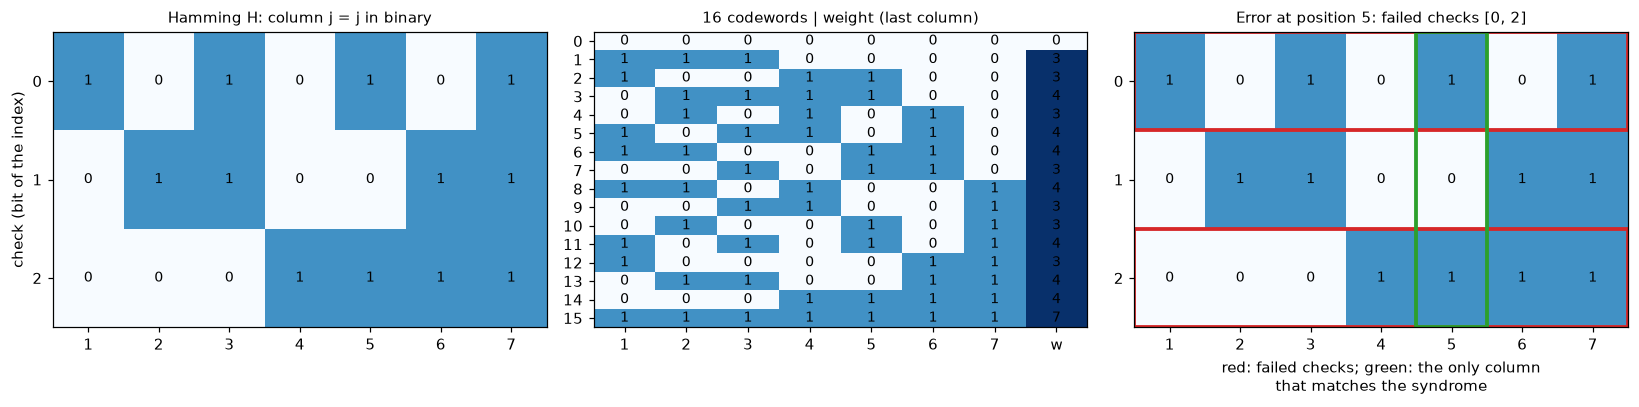

In [3]:
# Hamming (7,4): column j (j = 1..7) is j in binary (row b is bit b)
Hh = np.array([[(j >> b) & 1 for j in range(1, 8)] for b in range(3)])
words = np.array([[(w >> i) & 1 for i in range(7)] for w in range(128)])
cw = words[~((words @ Hh.T) % 2).any(1)]          # codewords = null space of H over GF(2)
wt = cw.sum(1)
print(f"Words of length 7: 128, codewords among them (H·cᵀ = 0): {len(cw)} = 2^(7−3)")
print("Weight distribution:", {int(a): int(b) for a, b in zip(*np.unique(wt, return_counts=True))},
      "→ d_min =", wt[wt > 0].min(), "(the difference of two codewords is also a codeword)")

c = cw[11]; e = np.zeros(7, int); e[4] = 1        # an error at position 5 (1-based)
r = (c + e) % 2
s = (Hh @ r) % 2
pos = int(s @ (1 << np.arange(3)))
print(f"\nc = {c}\ne = {e}\nr = c⊕e = {r}")
print(f"syndrome s = H·rᵀ = {s}ᵀ → binary {pos} → error at position {pos}; corrected: {np.array_equal((r + (np.arange(1, 8) == pos)) % 2, c)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1]})
def grid(a, M, title, xt=None):
    a.imshow(M, cmap="Blues", vmin=0, vmax=1.6, aspect="auto")
    for (i, j), v in np.ndenumerate(M): a.text(j, i, int(v), ha="center", va="center", fontsize=9)
    a.set_xticks(range(M.shape[1])); a.set_xticklabels(xt if xt is not None else range(M.shape[1]))
    a.set_yticks(range(M.shape[0])); a.grid(False); a.set_title(title, fontsize=10)
grid(ax[0], Hh, "Hamming H: column j = j in binary", range(1, 8)); ax[0].set_ylabel("check (bit of the index)")
grid(ax[1], np.c_[cw, wt], "16 codewords | weight (last column)", list(range(1, 8)) + ["w"])
grid(ax[2], Hh, f"Error at position {pos}: failed checks {np.nonzero(s)[0].tolist()}", range(1, 8))
for i in np.nonzero(s)[0]:
    ax[2].add_patch(plt.Rectangle((-0.5, i - 0.5), 7, 1, fill=False, ec="C3", lw=2.5))
ax[2].add_patch(plt.Rectangle((pos - 1.5, -0.5), 1, 3, fill=False, ec="C2", lw=2.5))
ax[2].set_xlabel("red: failed checks; green: the only column\nthat matches the syndrome")
plt.tight_layout(); plt.show()

## 2. The Gallager matrix step by step
We need an $m\times n$ matrix $H$, $m=n\,d_v/d_c$, with **$d_c$ ones in every row and $d_v$ in every column**. Gallager's construction (1962):
1. **Base band**: $n/d_c$ rows forming a "staircase". Row $i$ covers bits $i d_c,\dots,(i+1)d_c-1$. Every column has exactly one 1.
2. $d_v-1$ more bands, each a **random column permutation** of the base. A permutation keeps the row weight ($d_c$) and still gives one 1 per column.
3. Stack the bands → column weight $d_v$.

**Rank.** The rows of each band sum to the all-ones vector (each bit is covered exactly once). So sum of band 1 = sum of band 2 = …; these are $d_v-1$ linear dependencies, and $\mathrm{rank}\,H\le m-(d_v-1)$. That is why $k=n-\mathrm{rank}H$ is a bit more than $n/2$ and $R$ is a bit above $1/2$.

Below, step by step for $n=24$.

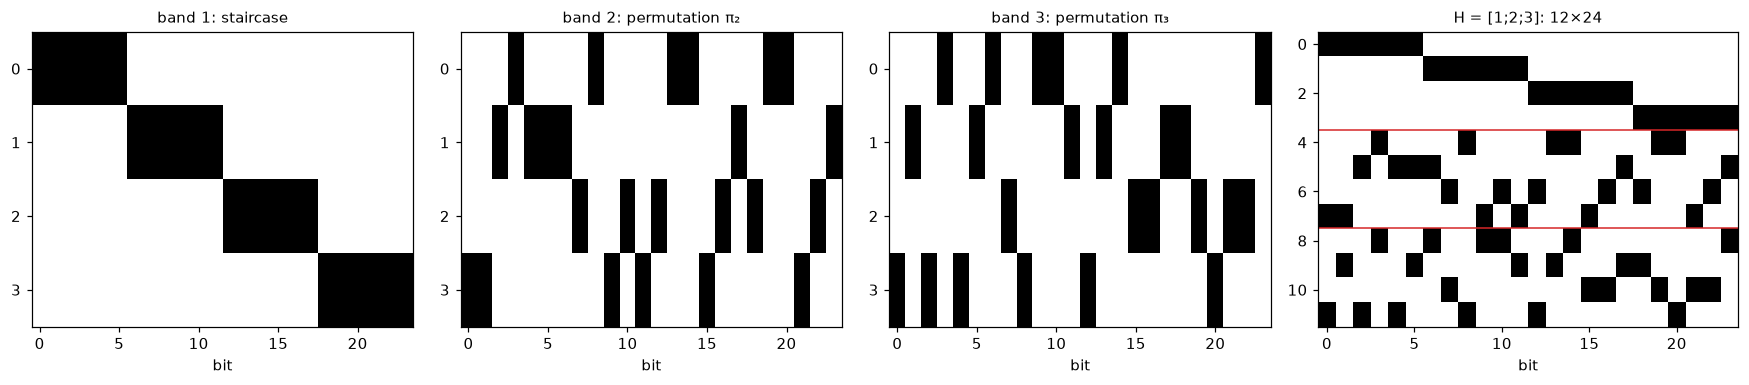

row weights: {np.int64(6)}  column weights: {np.int64(3)}
sum of the rows of band 1 (mod 2): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
sum of the rows of band 2 (mod 2): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
sum of the rows of band 3 (mod 2): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
m = 12, rank H = 10 = m − (d_v − 1) → k = n − rank = 14, R = 0.583 (nominal 1 − d_v/d_c = 0.500)


In [4]:
n_s = 24; mb = n_s // DC
r2 = np.random.default_rng(5)
base = np.zeros((mb, n_s), int)
for i in range(mb):
    base[i, i * DC:(i + 1) * DC] = 1              # step 1: staircase
perms = [np.arange(n_s)] + [r2.permutation(n_s) for _ in range(DV - 1)]
bands = [base[:, p] for p in perms]               # step 2: column permutations
Hs = np.vstack(bands)                             # step 3: stack the bands

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
for a, M, t in zip(ax, bands + [Hs], ["band 1: staircase", "band 2: permutation π₂", "band 3: permutation π₃",
                                      f"H = [1;2;3]: {Hs.shape[0]}×{Hs.shape[1]}"]):
    a.imshow(M, cmap="Greys", aspect="auto", interpolation="nearest"); a.set_title(t, fontsize=10); a.grid(False)
    a.set_yticks(range(0, M.shape[0], 1 if M.shape[0] <= mb else 2))
    a.set_xlabel("bit")
for b in range(1, DV): ax[3].axhline(b * mb - 0.5, color="C3", lw=1)
plt.tight_layout(); plt.show()

print("row weights:", set(Hs.sum(1)), " column weights:", set(Hs.sum(0)))
for b, M in enumerate(bands):
    print(f"sum of the rows of band {b + 1} (mod 2): {M.sum(0) % 2}")
rk = len(gf2_rref(Hs)[1])
print(f"m = {Hs.shape[0]}, rank H = {rk} = m − (d_v − 1) → k = n − rank = {n_s - rk}, R = {(n_s - rk) / n_s:.3f} (nominal 1 − d_v/d_c = {1 - DV / DC:.3f})")

## 3. Tanner graph, cycles and girth
Left: a toy (3,6) code on 12 bits. Circles are bits, squares are checks, and an edge is a one in $H$. Red shows who bit 0 "hears" in one iteration: 3 checks × 5 neighbours = 15 symbols. In a small code the neighbours repeat. These are **short cycles**: information comes back to the bit and gets counted twice, so BP is no longer exact. In the large code, 4-cycles are removed by construction, and a bit's neighbourhood stays almost a tree for several iterations.

Right: the full $H$ of the working code, $n=1008$: the same three bands as in section 2. It is a fraction of a percent full: 1008 bits have only 3024 edges, and the number of edges is what sets the decoder's complexity (linear in $n$).

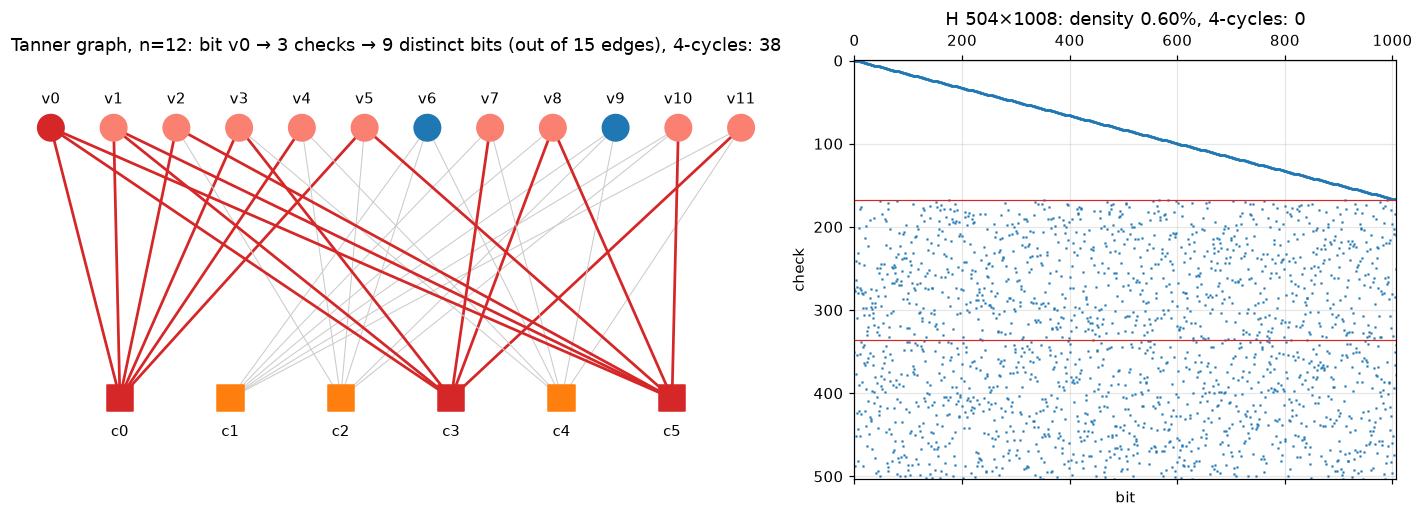

In [5]:
Ht = gallager_H(12, DV, DC, np.random.default_rng(3), fix_4cycles=False)
mt, nt = Ht.shape
xv, xc = np.linspace(0, 1, nt), np.linspace(0.1, 0.9, mt)
hot_chk = np.nonzero(Ht[:, 0])[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
a = ax[0]
for i, j in zip(*np.nonzero(Ht)):
    hot = i in hot_chk
    a.plot([xv[j], xc[i]], [1, 0], color="C3" if hot else "0.8", lw=1.8 if hot else 0.7, zorder=1)
heard = np.nonzero(Ht[hot_chk].any(0))[0]
a.scatter(xv, np.ones(nt), s=300, zorder=2, c=["C3" if j == 0 else ("salmon" if j in heard else "C0") for j in range(nt)])
a.scatter(xc, np.zeros(mt), s=300, marker="s", c=["C3" if i in hot_chk else "C1" for i in range(mt)], zorder=2)
for j in range(nt): a.text(xv[j], 1.09, f"v{j}", ha="center")
for i in range(mt): a.text(xc[i], -0.14, f"c{i}", ha="center")
a.set_ylim(-0.3, 1.25); a.axis("off")
a.set_title(f"Tanner graph, n=12: bit v0 → {len(hot_chk)} checks → {len(heard) - 1} distinct bits (out of 15 edges), 4-cycles: {count_4cycles(Ht)}")

ax[1].spy(H, markersize=0.4, aspect="auto")
for b in range(1, DV): ax[1].axhline(b * code.m / DV - 0.5, color="C3", lw=0.8)
ax[1].set_title(f"H {code.m}×{code.n}: density {H.mean():.2%}, 4-cycles: {count_4cycles(H)}")
ax[1].set_xlabel("bit"); ax[1].set_ylabel("check")
plt.tight_layout(); plt.show()

**Why cycles hurt.** BP is exact on a **tree**: all messages converging at a node are built from disjoint sets of symbols, so they are independent, and their LLRs can simply be added. A cycle of length $g$ (in edges) brings a bit's own information back to it after $g/2$ iterations. It gets counted again, as if it were new evidence.

- A **4-cycle** is two checks sharing ≥2 bits. We find them through the overlap matrix $O=HH^T$: $O_{ij}$ is the number of bits shared by checks $i$ and $j$; $O_{ij}\ge2$ means a 4-cycle. `gallager_H` keeps permuting columns until no such pairs remain.
- **Girth** is the length of the shortest cycle through a given bit. We compute it with breadth-first search: branches that leave the bit along different edges meet somewhere, and the sum of their depths + 1 is the cycle length.
- **Neighbourhood growth.** On a tree, after $\ell$ iterations a bit "hears" $1+15+150+1500+\dots$ bits. Already at $\ell=3$ that is more than $n=1008$, so the graph **must** close on itself. In the working code the girth is 6–8, so BP is exact for the first 3–4 iterations and an approximation after that (usually a good one: the cycles are long and varied, and the correlations are weak).

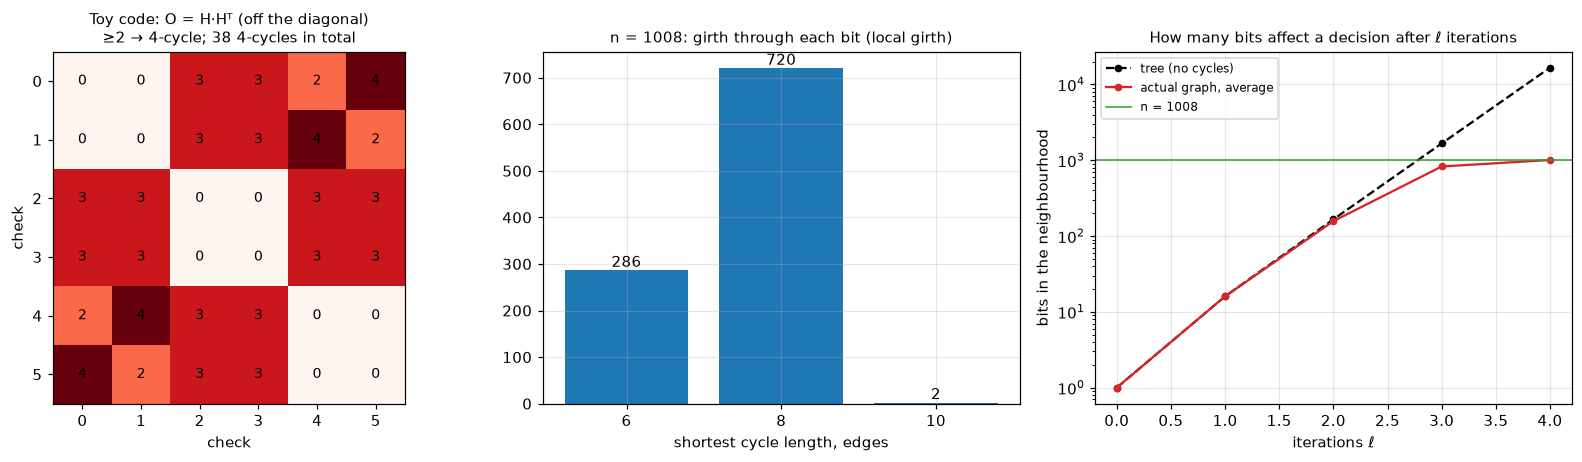

Girth: {6: 286, 8: 720, 10: 2} → a bit's own information comes back after 3–4 iterations
Neighbourhood (average over bits): [   1   16  157  828 1008]  tree: [    1    16   166  1666 16666]


In [6]:
from collections import deque
nb_v = [np.nonzero(H[:, j])[0] for j in range(code.n)]      # checks of each bit
nb_c = [np.nonzero(H[i])[0] for i in range(code.m)]         # bits of each check

def girth_at(v0):
    # BFS on the bipartite graph: nodes 0..n−1 are bits, n..n+m−1 are checks
    dist, branch, par = {v0: 0}, {v0: -1}, {v0: None}
    q, best = deque([v0]), np.inf
    while q:
        u = q.popleft()
        if 2 * dist[u] + 1 >= best: break
        for w in (nb_v[u] + code.n if u < code.n else nb_c[u - code.n]):
            w = int(w)
            if w == par[u]: continue
            if w in dist:                         # two branches meet → a cycle
                if branch[w] != branch[u]: best = min(best, dist[u] + dist[w] + 1)
            else:
                dist[w], par[w] = dist[u] + 1, u
                branch[w] = w if u == v0 else branch[u]
                q.append(w)
    return best

def growth(v0, depth=4):
    seen, front, out = {v0}, {v0}, [1]
    for _ in range(depth):
        chk = set(np.concatenate([nb_v[b] for b in front]).tolist())
        new = set(np.concatenate([nb_c[c] for c in chk]).tolist()) - seen
        seen |= new; front = new; out.append(len(seen))
    return out

g = np.array([girth_at(v) for v in range(code.n)])
gr = np.array([growth(v) for v in range(0, code.n, 8)])
tree = np.cumsum([1] + [DV * (DC - 1) * ((DV - 1) * (DC - 1)) ** l for l in range(4)])

Ot = (Ht @ Ht.T); np.fill_diagonal(Ot, 0)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].imshow(Ot, cmap="Reds", vmin=0, vmax=4); ax[0].grid(False)
for (i, j), v in np.ndenumerate(Ot): ax[0].text(j, i, v, ha="center", va="center", fontsize=9)
ax[0].set_title(f"Toy code: O = H·Hᵀ (off the diagonal)\n≥2 → 4-cycle; {count_4cycles(Ht)} 4-cycles in total", fontsize=10)
ax[0].set_xlabel("check"); ax[0].set_ylabel("check")
u_, c_ = np.unique(g, return_counts=True)
ax[1].bar([str(int(x)) for x in u_], c_, color="C0")
for x, y in zip(range(len(u_)), c_): ax[1].text(x, y, y, ha="center", va="bottom")
ax[1].set_title(f"n = {code.n}: girth through each bit (local girth)", fontsize=10); ax[1].set_xlabel("shortest cycle length, edges")
ax[2].semilogy(range(5), tree, "k--o", ms=4, label="tree (no cycles)")
ax[2].semilogy(range(5), gr.mean(0), "C3-o", ms=4, label="actual graph, average")
ax[2].axhline(code.n, color="C2", lw=1, label=f"n = {code.n}")
ax[2].set_xlabel("iterations ℓ"); ax[2].set_ylabel("bits in the neighbourhood"); ax[2].legend(fontsize=8)
ax[2].set_title("How many bits affect a decision after ℓ iterations", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Girth: {dict(zip(u_.astype(int).tolist(), c_.tolist()))} → a bit's own information comes back after {int(g.min()) // 2}–{int(np.median(g)) // 2} iterations")
print("Neighbourhood (average over bits):", np.round(gr.mean(0)).astype(int), " tree:", tree)

## 4. Encoding over GF(2)
$H$ defines the **checks**, but the transmitter needs a **generator**: a rule that turns $k$ data bits $\mathbf u$ into $\mathbf c$ with $H\mathbf c^T=0$.

**Gaussian elimination over GF(2)** (`gf2_rref`): addition is XOR, multiplication is AND, and there is no division (the only nonzero element is 1). Go column by column: find a row with a 1 in the current column (the **pivot**), swap it to the top, and XOR it into every other row that has a 1 in that column. The result is the row-reduced form $A$ (the same checks written differently) and a split of the columns:
- **pivot columns** → parity bits ($\mathrm{rank}H$ of them),
- **the rest** → information bits ($k=n-\mathrm{rank}H$).

Row $i$ of $A$ has a single 1 among the pivots, in column $p_i$. So check $i$ reads
$$c_{p_i}=\bigoplus_{j\in\text{info}}A_{ij}\,u_j\quad\Longrightarrow\quad \mathbf c_\text{piv}=P\,\mathbf u,\qquad P=A[:,\text{info}].$$
This is the systematic encoder `encode`: the data go into the information positions unchanged, and the parity bits are computed by multiplying by $P$.

**The cost.** $H$ is sparse, but $P$ is **dense** (≈27% ones in the working code, vs. 0.6% in $H$), so encoding costs $O(n^2)$ XORs. That is why standards (Wi-Fi, 5G NR) make the parity part of $H$ dual-diagonal/quasi-cyclic: the encoder is then linear in $n$ and works by back-substitution without Gaussian elimination.

**Why we could just as well send all zeros.** The code is linear, the channel is symmetric ($y\to-y$ when $x\to-x$), and the decoder is symmetric, so the error probability doesn't depend on the transmitted word. Theoretical analysis (section 13) therefore uses the all-zero codeword; in the simulations we honestly encode random data.

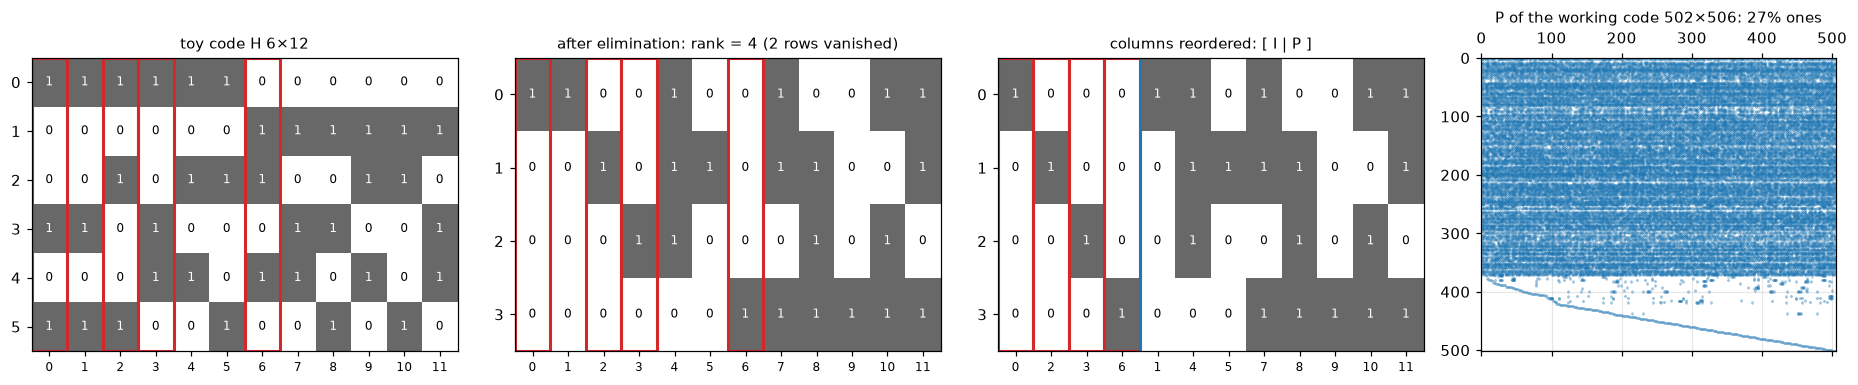

pivots (parity bits): [0 2 3 6],  information bits: [ 1  4  5  7  8  9 10 11]
u = [1 0 1 1 0 0 1 0] → c = [1 1 0 1 0 1 0 1 0 0 1 0]  (c[info] = [1 0 1 1 0 0 1 0] = u)
H·cᵀ = [0 0 0 0 0 0]

Working code: encoding ≈ 68926 XORs (dense P) vs. 3024 edges in one decoder iteration
Encoder: H·cᵀ = 0 for random words: True


In [7]:
toy = LDPC(Ht)
A_t, piv_t, info_t = toy.A, toy.piv, toy.info
order = np.r_[piv_t, info_t]                      # reorder columns: [pivots | data] → A = [I | P]
u_t = np.array([[1, 0, 1, 1, 0, 0, 1, 0]])[:, :toy.k]
c_t = toy.encode(u_t)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1.2, 1.2, 1.2, 1]})
def bits(a, M, title, xt, hl=()):
    a.imshow(M, cmap="Greys", vmin=0, vmax=1.5, aspect="auto"); a.grid(False)
    for (i, j), v in np.ndenumerate(M): a.text(j, i, int(v), ha="center", va="center", fontsize=8, color="w" if v else "k")
    a.set_xticks(range(M.shape[1])); a.set_xticklabels(xt, fontsize=8); a.set_yticks(range(M.shape[0])); a.set_title(title, fontsize=10)
    for j in hl: a.add_patch(plt.Rectangle((j - 0.5, -0.5), 1, M.shape[0], fill=False, ec="C3", lw=2))
bits(ax[0], Ht, f"toy code H {Ht.shape[0]}×{Ht.shape[1]}", range(toy.n), piv_t)
bits(ax[1], A_t, f"after elimination: rank = {len(piv_t)} (2 rows vanished)", range(toy.n), piv_t)
bits(ax[2], A_t[:, order], "columns reordered: [ I | P ]", order, range(len(piv_t)))
ax[2].axvline(len(piv_t) - 0.5, color="C0", lw=2)
ax[3].spy(code.P, markersize=0.05, aspect="auto"); ax[3].set_title(f"P of the working code {code.P.shape[0]}×{code.P.shape[1]}: {code.P.mean():.0%} ones", fontsize=10)
plt.tight_layout(); plt.show()

print(f"pivots (parity bits): {piv_t},  information bits: {info_t}")
print(f"u = {u_t[0]} → c = {c_t[0]}  (c[info] = {c_t[0, info_t]} = u)")
print(f"H·cᵀ = {(Ht @ c_t[0]) % 2}")
print(f"\nWorking code: encoding ≈ {int(code.P.sum())} XORs (dense P) vs. {code.E} edges in one decoder iteration")
U = rng.integers(0, 2, (5, code.k))
print("Encoder: H·cᵀ = 0 for random words:", code.syndrome_ok(code.encode(U)).all())

## 5. Channel → LLR
**Where $2y/\sigma^2$ comes from.** By Bayes' rule with equiprobable bits,
$$L=\ln\frac{p(y\,|\,x=+1)}{p(y\,|\,x=-1)}=\ln\frac{e^{-(y-1)^2/2\sigma^2}}{e^{-(y+1)^2/2\sigma^2}}=\frac{(y+1)^2-(y-1)^2}{2\sigma^2}=\frac{2y}{\sigma^2}.$$
Going back: $P(c=1\,|\,L)=\dfrac1{1+e^{L}}$, $P(c=0\,|\,L)=\dfrac1{1+e^{-L}}$. $|L|=2$ means a 12% chance of error, $|L|=5$ means 0.7%, $|L|=10$ means $5\cdot10^{-5}$. LLRs are convenient because independent evidence **adds up** (a product of likelihoods becomes a sum of logs), and the denominator $p(y)$ cancels.

**Why $\mathcal N(\mu,2\mu)$.** For $x=+1$: $y\sim\mathcal N(1,\sigma^2)$ → $L=2y/\sigma^2\sim\mathcal N\big(2/\sigma^2,\;4/\sigma^2\big)$, so the variance is exactly twice the mean. This property ("symmetry" or consistency) survives the addition of LLRs at bit nodes, and the Gaussian approximation of section 11 rests on it.

At $E_b/N_0$ = `EBN0_DB`, each symbol gets $E_s/N_0=R\,E_b/N_0$, noticeably below 0 dB. A hard sign decision is wrong on roughly every 8th symbol. Right: the LLR multiplied by the transmitted sign, so correct decisions are to the right of zero and errors to the left. The Gaussian $\mathcal N(\mu,2\mu)$ is the theory. Far right: how an LLR turns into an error probability.

The key number is **how much information about a bit one symbol carries**, $I=J(\sqrt{8RE_b/N_0})$. If $I>R$, a code can in principle fix everything (Shannon); if $I<R$, no decoder can help.

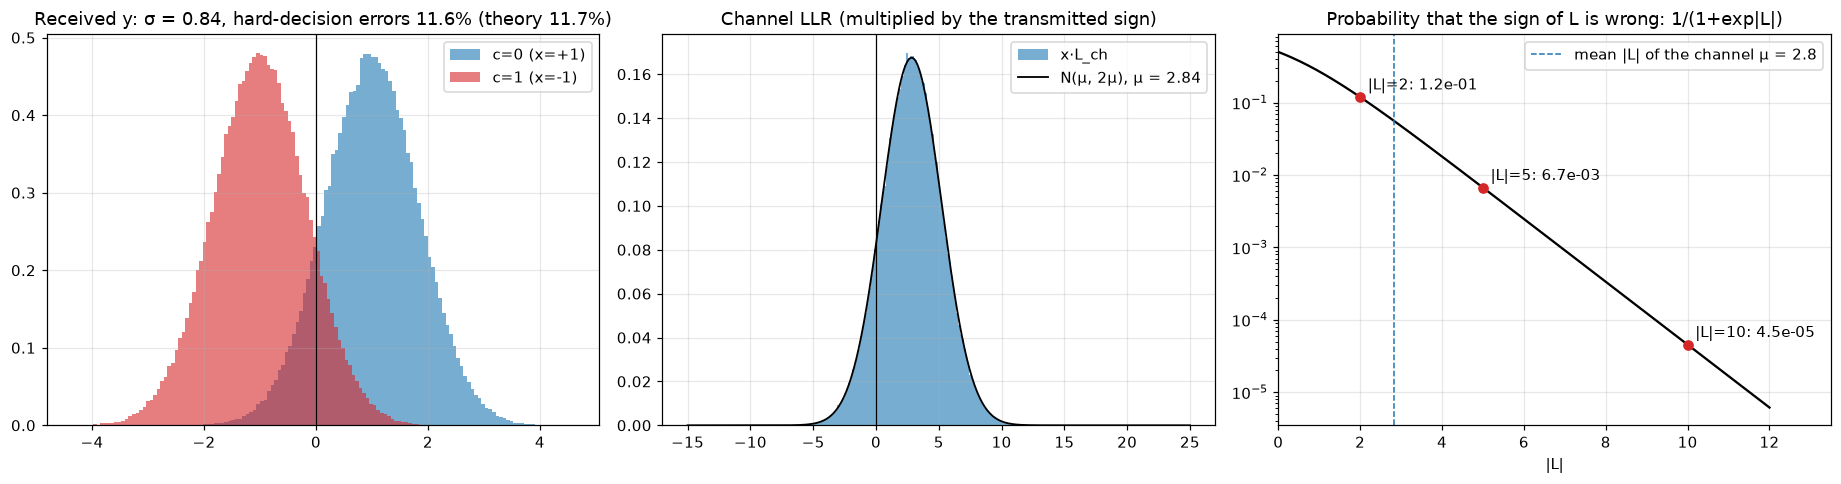

Information per symbol: measured 0.604 bit, theory J(σ_ch) = 0.604 bit, need R = 0.502 bit → there is margin


In [8]:
U = rng.integers(0, 2, (400, code.k))
C = code.encode(U); X = 1 - 2.0 * C
y, L, sigma = channel(C, EBN0_DB, code.R, rng)
mu = 2 / sigma**2

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for c, col in [(0, "C0"), (1, "C3")]:
    ax[0].hist(y[C == c], 120, density=True, alpha=0.6, color=col, label=f"c={c} (x={1-2*c:+d})")
ax[0].axvline(0, color="k", lw=0.8); ax[0].legend()
ax[0].set_title(f"Received y: σ = {sigma:.2f}, hard-decision errors {np.mean((y < 0) != C):.1%} "
                f"(theory {0.5*erfc(np.sqrt(code.R*10**(EBN0_DB/10))):.1%})")
l = np.linspace(-15, 25, 400)
ax[1].hist((L * X).ravel(), 150, density=True, alpha=0.6, label="x·L_ch")
ax[1].plot(l, np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu), "k", lw=1.2, label=f"N(μ, 2μ), μ = {mu:.2f}")
ax[1].axvline(0, color="k", lw=0.8); ax[1].legend()
ax[1].set_title("Channel LLR (multiplied by the transmitted sign)")
ll = np.linspace(0, 12, 300)
ax[2].semilogy(ll, 1 / (1 + np.exp(ll)), "k")
for v in [2, 5, 10]:
    ax[2].plot(v, 1 / (1 + np.exp(v)), "C3o"); ax[2].annotate(f"|L|={v}: {1 / (1 + np.exp(v)):.1e}", (v, 1 / (1 + np.exp(v))), xytext=(5, 5), textcoords="offset points")
ax[2].axvline(mu, color="C0", ls="--", lw=1, label=f"mean |L| of the channel μ = {mu:.1f}"); ax[2].legend()
ax[2].set_xlim(0, 13.5); ax[2].set_xlabel("|L|"); ax[2].set_title("Probability that the sign of L is wrong: 1/(1+exp|L|)")
plt.tight_layout(); plt.show()

print(f"Information per symbol: measured {mi(L, X):.3f} bit, theory J(σ_ch) = {J(sch(EBN0_DB, code.R)):.3f} bit, "
      f"need R = {code.R:.3f} bit → {'there is margin' if J(sch(EBN0_DB, code.R)) > code.R else 'NO margin'}")

## 6. The check node: the ⊞ operation, the tanh rule and min-sum
A check says $v_1\oplus v_2\oplus\dots\oplus v_{d_c}=0$, i.e. each bit equals the XOR of the others. What does the check know about bit $v$ if it knows the LLRs of the others?

**Two bits.** Let $p_i=P(v_i=0)$, $q_i=1-p_i$. Then $P(v_1\oplus v_2=0)=p_1p_2+q_1q_2$, and
$$P(v_1\oplus v_2=0)-P(v_1\oplus v_2=1)=(p_1-q_1)(p_2-q_2).$$
The difference of probabilities in terms of the LLR: $p-q=\dfrac{e^{L/2}-e^{-L/2}}{e^{L/2}+e^{-L/2}}=\tanh\dfrac L2$. Hence
$$\tanh\frac{L_1\boxplus L_2}{2}=\tanh\frac{L_1}{2}\tanh\frac{L_2}{2},\qquad\text{and by induction}\qquad \tanh\frac{L_{c\to v}}{2}=\prod_{v'\ne v}\tanh\frac{L_{v'\to c}}{2}.$$

**Properties of ⊞** (see the figure):
- the sign of the result is the product of the signs (just the XOR of the hard decisions);
- $|L_1\boxplus L_2|\le\min(|L_1|,|L_2|)$, the **weakest link**: if nothing is known about one bit ($L=0$), nothing is known about the XOR either. That is why $d_c$ must be small;
- **min-sum**: $L_1\boxplus L_2\approx\operatorname{sign}L_1\operatorname{sign}L_2\cdot\min(|L_1|,|L_2|)$. It is exact when one input is much weaker than the others and **overestimates** confidence when the inputs are comparable. A factor $\alpha<1$ compensates for the overestimate on average. Right: the best $\alpha$ estimated straight from data, as the least-squares slope of exact ⊞ vs. min-sum on 5 channel inputs.

Below, the tanh rule is checked by brute force over all $2^5$ bit combinations.

input LLRs: [ 2.1 -3.4  0.9  4.2  1.6]
brute force over 32 combinations: P(XOR = 1) = 0.59941 → LLR = ln(P0/P1) = -0.40302
tanh rule:  ⊞ = -0.40302
min-sum:    -0.90000  (weakest input +0.90)


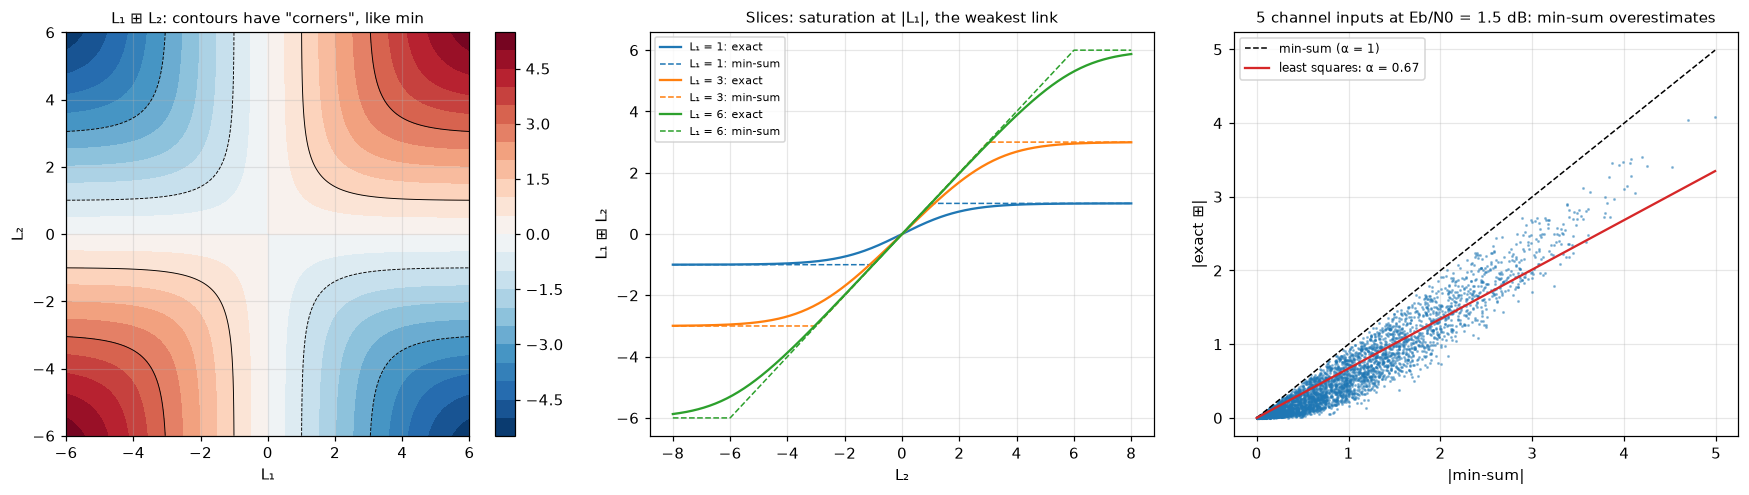

Normalization estimated from the channel: α ≈ 0.67 (the decoder uses ALPHA_MS = 0.8; in later iterations the inputs are larger and α is closer to 1)


In [9]:
Lin = np.array([2.1, -3.4, 0.9, 4.2, 1.6])[:DC - 1]   # five inputs: one weak, one negative
p1 = 1 / (1 + np.exp(Lin))                        # P(bit = 1)
combos = np.array([[(w >> i) & 1 for i in range(DC - 1)] for w in range(2 ** (DC - 1))])
Pc = np.prod(np.where(combos, p1, 1 - p1), 1)
p_x1 = Pc[combos.sum(1) % 2 == 1].sum()
print(f"input LLRs: {np.round(Lin, 2)}")
print(f"brute force over {2 ** (DC - 1)} combinations: P(XOR = 1) = {p_x1:.5f} → LLR = ln(P0/P1) = {np.log((1 - p_x1) / p_x1):+.5f}")
print(f"tanh rule:  ⊞ = {boxplus(*Lin):+.5f}")
print(f"min-sum:    {np.prod(np.sign(Lin)) * np.abs(Lin).min():+.5f}  (weakest input {Lin[np.abs(Lin).argmin()]:+.2f})")

l1 = np.linspace(-6, 6, 241)
G1, G2 = np.meshgrid(l1, l1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
cs = ax[0].contourf(G1, G2, boxplus(G1, G2), 21, cmap="RdBu_r"); plt.colorbar(cs, ax=ax[0])
ax[0].contour(G1, G2, boxplus(G1, G2), [-3, -1, 1, 3], colors="k", linewidths=0.6)
ax[0].set_xlabel("L₁"); ax[0].set_ylabel("L₂"); ax[0].set_title("L₁ ⊞ L₂: contours have \"corners\", like min", fontsize=10); ax[0].set_aspect("equal")
lx = np.linspace(-8, 8, 400)
for a1, col in [(1, "C0"), (3, "C1"), (6, "C2")]:
    ax[1].plot(lx, boxplus(a1, lx), col, label=f"L₁ = {a1}: exact")
    ax[1].plot(lx, np.sign(lx) * np.minimum(a1, np.abs(lx)), col, ls="--", lw=1, label=f"L₁ = {a1}: min-sum")
ax[1].set_xlabel("L₂"); ax[1].set_ylabel("L₁ ⊞ L₂"); ax[1].legend(fontsize=7); ax[1].set_title("Slices: saturation at |L₁|, the weakest link", fontsize=10)

_, Lsmp, _ = channel(np.zeros((4000, DC - 1), np.uint8), EBN0_DB, code.R, rng)    # 5 inputs from the channel
ex = np.abs(boxplus(*Lsmp.T)); ms = np.abs(Lsmp).min(1)
a_fit = np.sum(ex * ms) / np.sum(ms ** 2)
ax[2].plot(ms, ex, ".", ms=2, alpha=0.4)
mm = np.linspace(0, ms.max(), 2)
ax[2].plot(mm, mm, "k--", lw=1, label="min-sum (α = 1)"); ax[2].plot(mm, a_fit * mm, "C3", lw=1.5, label=f"least squares: α = {a_fit:.2f}")
ax[2].set_xlabel("|min-sum|"); ax[2].set_ylabel("|exact ⊞|"); ax[2].legend(fontsize=8)
ax[2].set_title(f"{DC - 1} channel inputs at Eb/N0 = {EBN0_DB} dB: min-sum overestimates", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Normalization estimated from the channel: α ≈ {a_fit:.2f} (the decoder uses ALPHA_MS = {ALPHA_MS}; in later iterations the inputs are larger and α is closer to 1)")

## 7. The bit node: adding up evidence, and the extrinsic principle
Bit $v$ receives $d_v$ messages from its checks plus the channel LLR. If they are independent, the likelihoods multiply and the LLRs **add**:
$$L_v^\text{post}=L_\text{ch}+\sum_{c\in N(v)}L_{c\to v}.$$
The sign of $L_v^\text{post}$ is the current decision; the syndrome is checked on it for early stopping.

**Extrinsic.** To check $c$ the bit sends the sum **without** that check's own contribution:
$$L_{v\to c}=L_v^\text{post}-L_{c\to v}.$$
Otherwise, in the next iteration the check gets its own opinion back, takes it for independent confirmation and amplifies it: positive feedback. Confidence grows exponentially, but the errors stay: the decoder "talks itself into it". The same "don't send the sender its own message" rule applies at the check node (`loo_prod` is the product over all inputs *except* one's own).

Experiment: the working code, the same noise, a decoder with extrinsic messages and one with the "echo".

extrinsic (correct)   : BER = 1.58e-02, FER = 0.27


echo: L_v→c = L_post  : BER = 8.22e-02, FER = 0.97


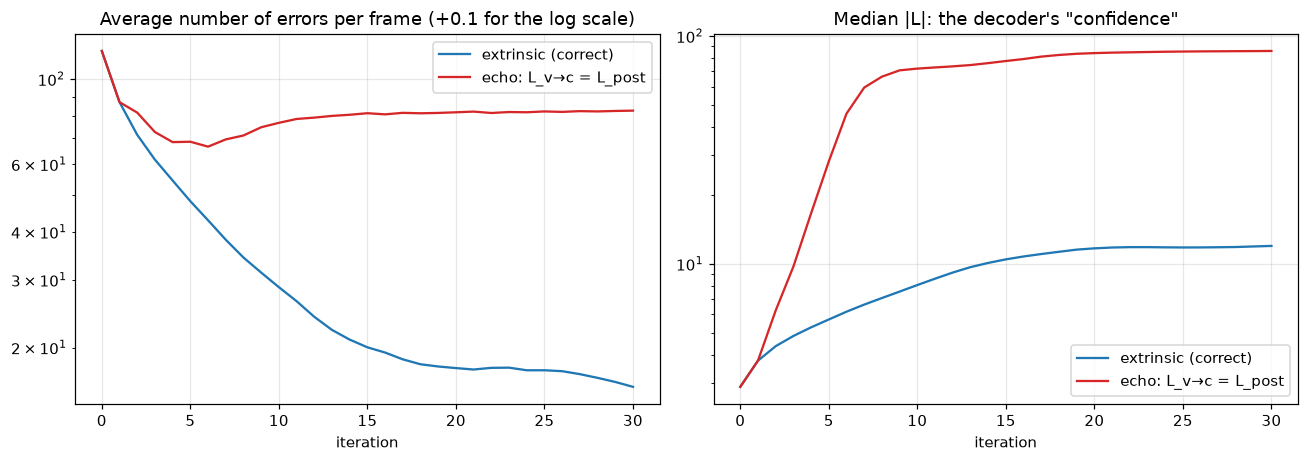

In [10]:
F7 = 200
U = rng.integers(0, 2, (F7, code.k)); C = code.encode(U); X = 1 - 2.0 * C
_, L7, _ = channel(C, EBN0_DB, code.R, rng)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for ext, col, name in [(True, "C0", "extrinsic (correct)"), (False, "C3", "echo: L_v→c = L_post")]:
    tr = []
    Ch, nit = code.decode(L7, 30, "spa", cb=lambda it, Lv, Lcv: tr.append(((Lv * X < 0).sum(1).mean(), np.median(np.abs(Lv)))), extrinsic=ext)
    tr = np.array(tr)
    ax[0].semilogy(tr[:, 0] + 0.1, col, label=name); ax[1].semilogy(tr[:, 1], col, label=name)
    print(f"{name:22s}: BER = {np.mean(Ch[:, code.info] != U):.2e}, FER = {1 - code.syndrome_ok(Ch).mean():.2f}")
ax[0].set_title("Average number of errors per frame (+0.1 for the log scale)"); ax[1].set_title("Median |L|: the decoder's \"confidence\"")
for a in ax: a.set_xlabel("iteration"); a.legend()
plt.tight_layout(); plt.show()

## 8. BP by hand on a 12-bit code
Take the toy code from section 3 ($n=12$, $k=8$), send a random codeword and pick a noise realization where the channel made **two errors** and BP fixes them, but not in the first iteration. We print the first iteration for an erroneous bit in full, then watch how the messages change from iteration to iteration.

In the figures the colour is the LLR **multiplied by the transmitted sign** $x$: blue means "right and confident", red means "wrong". Check squares are green when the current hard decision satisfies them. Edge thickness is $|L_{c\to v}|$; edge colour shows whether the message helps the bit (blue) or pulls it toward an error (red).

Note: the 12-bit code has many 4-cycles (section 3), so the messages quickly become correlated. Even so, the two errors get fixed.

In [11]:
for seed in range(1000):                          # look for noise: 2 channel errors, BP fixes them in ≥3 iterations
    rs = np.random.default_rng(seed)
    u8 = rs.integers(0, 2, (1, toy.k)); c8 = toy.encode(u8); x8 = 1 - 2.0 * c8[0]
    _, L8, _ = channel(c8, 3.0, toy.R, rs)
    if ((L8[0] < 0) != c8[0]).sum() == 2:
        Ch8, nit8 = toy.decode(L8, 20, "spa")
        if (Ch8 == c8).all() and nit8[0] >= 3: break
Lch8 = L8[0]
err8 = np.nonzero((Lch8 < 0) != c8[0])[0]
print(f"seed = {seed}: c = {c8[0]}, channel errors in bits {err8}, BP converged in {nit8[0]} iterations")
print("x·L_ch =", np.round(Lch8 * x8, 2))

# ── the first iteration, unrolled, for the first erroneous bit ──
v = err8[0]
print(f"\nIteration 1, bit v{v}: L_ch = {Lch8[v]:+.2f} (sent x = {x8[v]:+.0f} → wrong sign)")
tot = Lch8[v]
for cc in np.nonzero(Ht[:, v])[0]:
    others = [int(j) for j in np.nonzero(Ht[cc])[0] if j != v]
    Lin_ = Lch8[others]                           # in iteration 1 a bit sends its L_ch to the check (L_c→v is still 0)
    t = np.tanh(Lin_ / 2)
    out = 2 * np.arctanh(np.prod(t))
    ms_ = ALPHA_MS * np.prod(np.sign(Lin_)) * np.abs(Lin_).min()
    print(f"  c{cc}: inputs from v{others} = {np.round(Lin_, 2)}")
    print(f"       tanh(L/2) = {np.round(t, 3)}, product = {np.prod(t):+.4f} → L_c{cc}→v{v} = {out:+.2f}   (min-sum·α: {ms_:+.2f})")
    tot += out
print(f"  a-posteriori L_v{v} = L_ch + Σ = {tot:+.2f} → sign {'fixed' if tot * x8[v] > 0 else 'still wrong'}")

tr8 = []
toy.decode(L8, 20, "spa", cb=lambda it, Lv, Lcv: tr8.append((Lv[0].copy(), Lcv[0].copy())))
print(f"  cross-check with the decoder: L_v{v} after iteration 1 = {tr8[1][0][v]:+.2f}")

seed = 302: c = [1 1 0 0 1 1 0 1 0 1 1 1], channel errors in bits [1 4], BP converged in 4 iterations
x·L_ch = [ 6.75 -0.34  9.92  7.29 -2.43  0.3   6.86 12.13  2.23  5.04  9.29  2.  ]

Iteration 1, bit v1: L_ch = +0.34 (sent x = -1 → wrong sign)
  c0: inputs from v[0, 2, 3, 4, 5] = [-6.75  9.92  7.29  2.43 -0.3 ]
       tanh(L/2) = [-0.998  1.     0.999  0.838 -0.148], product = +0.1237 → L_c0→v1 = +0.25   (min-sum·α: +0.24)
  c3: inputs from v[0, 3, 7, 8, 11] = [ -6.75   7.29 -12.13   2.23  -2.  ]
       tanh(L/2) = [-0.998  0.999 -1.     0.806 -0.761], product = -0.6109 → L_c3→v1 = -1.42   (min-sum·α: -1.60)
  c5: inputs from v[0, 2, 5, 8, 10] = [-6.75  9.92 -0.3   2.23 -9.29]
       tanh(L/2) = [-0.998  1.    -0.148  0.806 -1.   ], product = -0.1190 → L_c5→v1 = -0.24   (min-sum·α: -0.24)
  a-posteriori L_v1 = L_ch + Σ = -1.07 → sign fixed
  cross-check with the decoder: L_v1 after iteration 1 = -1.07


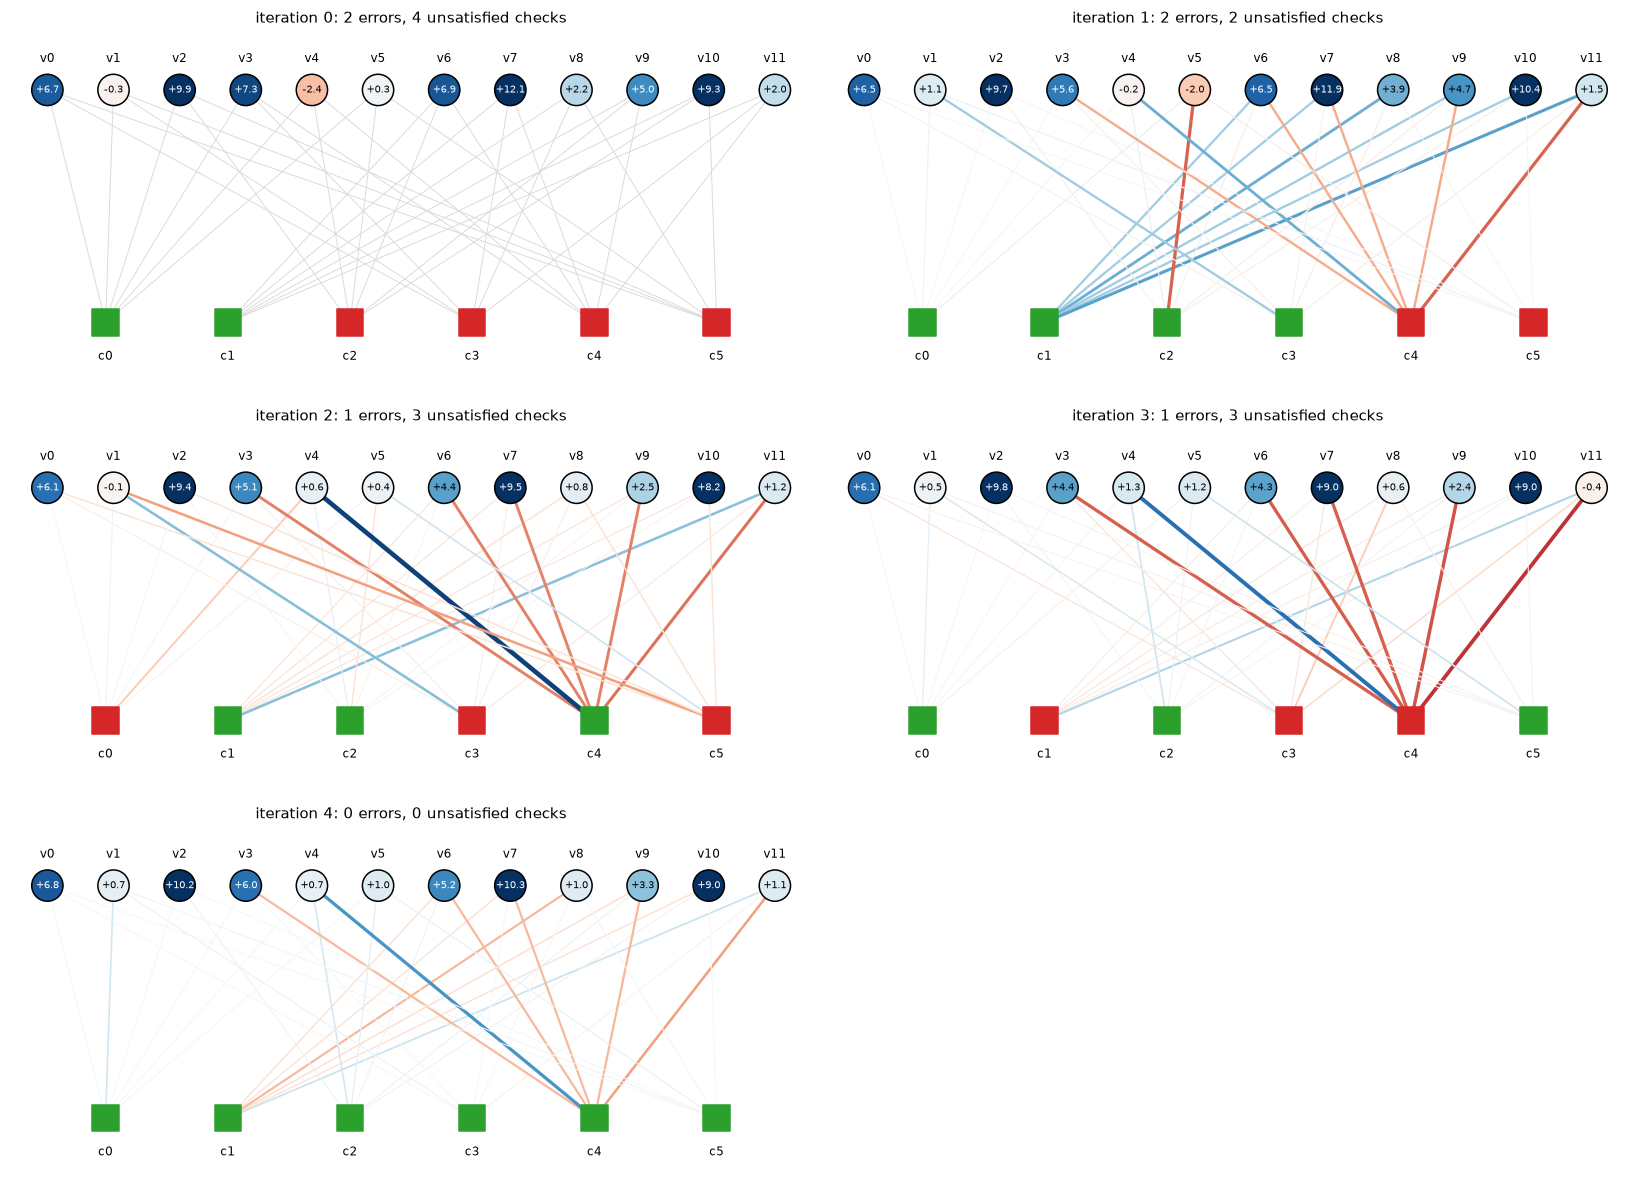

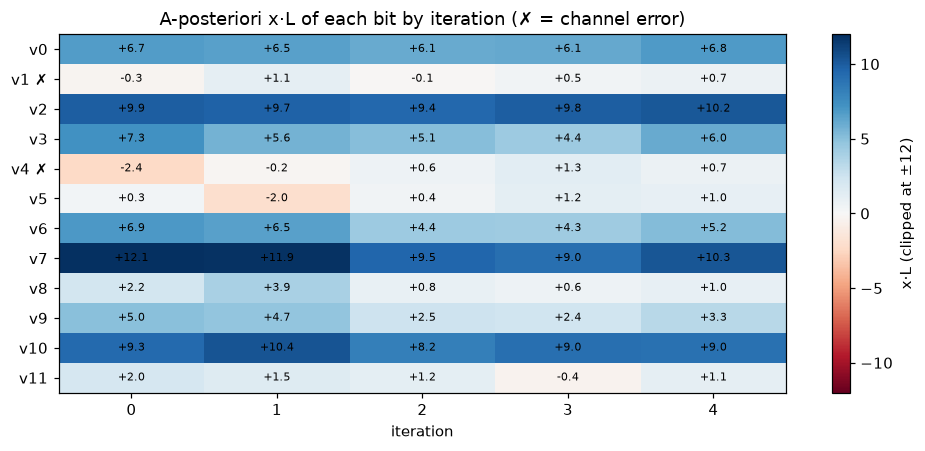

In [12]:
def draw_tanner(a, Hm, xL, xLcv, title, vmax=8, emax=4):
    m_, n_ = Hm.shape
    xv_, xc_ = np.linspace(0, 1, n_), np.linspace(0.08, 0.92, m_)
    cm = plt.cm.RdBu
    rr, cc_ = np.nonzero(Hm)                      # edges in the same order as in LDPC (by check)
    for e, (i, j) in enumerate(zip(rr, cc_)):
        w = xLcv[e]
        a.plot([xv_[j], xc_[i]], [1, 0], color=cm(0.5 + np.clip(w, -emax, emax) / (2 * emax)) if w != 0 else "0.85",
               lw=0.6 + 2.6 * min(abs(w), emax) / emax, zorder=1)
    a.scatter(xv_, np.ones(n_), s=420, c=np.clip(xL, -vmax, vmax), cmap=cm, vmin=-vmax, vmax=vmax, edgecolors="k", zorder=2)
    for j in range(n_): a.text(xv_[j], 1, f"{xL[j]:+.1f}", ha="center", va="center", fontsize=6.5, zorder=3,
                                   color="w" if abs(xL[j]) > 0.6 * vmax else "k")
    hard = (xL < 0).astype(int)                   # errors = bits with the wrong sign; syndrome of errors = syndrome of the decision
    sat = (Hm @ hard) % 2 == 0
    a.scatter(xc_, np.zeros(m_), s=300, marker="s", c=["C2" if s_ else "C3" for s_ in sat], zorder=2)
    for j in range(n_): a.text(xv_[j], 1.12, f"v{j}", ha="center", fontsize=8)
    for i in range(m_): a.text(xc_[i], -0.16, f"c{i}", ha="center", fontsize=8)
    a.set_ylim(-0.3, 1.25); a.axis("off"); a.set_title(title, fontsize=10)

xe8 = x8[toy.ev]
snaps = list(range(min(len(tr8), 6)))
fig, ax = plt.subplots(3, 2, figsize=(15, 11))
for a in ax.ravel()[len(snaps):]: a.axis("off")
for a, it in zip(ax.ravel(), snaps):
    xL, Lc = tr8[it][0] * x8, tr8[it][1] * xe8
    draw_tanner(a, Ht, xL, Lc, f"iteration {it}: {(xL < 0).sum()} errors, {((Ht @ (xL < 0)) % 2).sum()} unsatisfied checks")
plt.tight_layout(); plt.show()

M8 = np.array([t[0] * x8 for t in tr8]).T
fig, a = plt.subplots(figsize=(1.2 * len(tr8) + 3, 4.2))
im = a.imshow(np.clip(M8, -12, 12), cmap="RdBu", vmin=-12, vmax=12, aspect="auto"); plt.colorbar(im, ax=a, label="x·L (clipped at ±12)")
for (j, it), val in np.ndenumerate(M8): a.text(it, j, f"{val:+.1f}", ha="center", va="center", fontsize=7)
a.set_yticks(range(toy.n)); a.set_yticklabels([f"v{j}" + (" ✗" if j in err8 else "") for j in range(toy.n)])
a.set_xticks(range(len(tr8))); a.set_xlabel("iteration"); a.grid(False)
a.set_title("A-posteriori x·L of each bit by iteration (✗ = channel error)")
plt.tight_layout(); plt.show()

## 9. The vectorized decoder: inside the `LDPC` class
Writing BP as loops over nodes is slow. In `LDPC` everything reduces to operations on an **array of edges** of length $E=n d_v=m d_c$:

- `np.nonzero(H)` lists the ones of $H$ row by row → the edges are **ordered by check**: the edges of check $i$ are $i d_c,\dots,(i+1)d_c-1$. So `Lvc.reshape(F, m, dc)` immediately gives each check its $d_c$ inputs, and `check_update` works along the last axis.
- `ev[e]` is the bit at the end of edge $e$: `La[:, ev]` copies each bit's a-posteriori LLR onto all of its edges.
- `var` ($n\times d_v$) holds the edge indices of each bit (an `argsort` of `ev`): `Lcv[:, var].sum(-1)` gathers the check messages arriving at each bit.
- `loo_prod` is the "product of all but oneself", computed with prefix and suffix products: $O(d_c)$ instead of $O(d_c^2)$, and no division by $\tanh\approx0$.
- min-sum: each output needs the minimum of the **other** inputs. That is the first minimum for everyone except the minimal input itself, which gets the second minimum.
- `layers` splits the checks into layers that share no bits (for the layered schedule, section 14). For a Gallager code the layers are the bands.

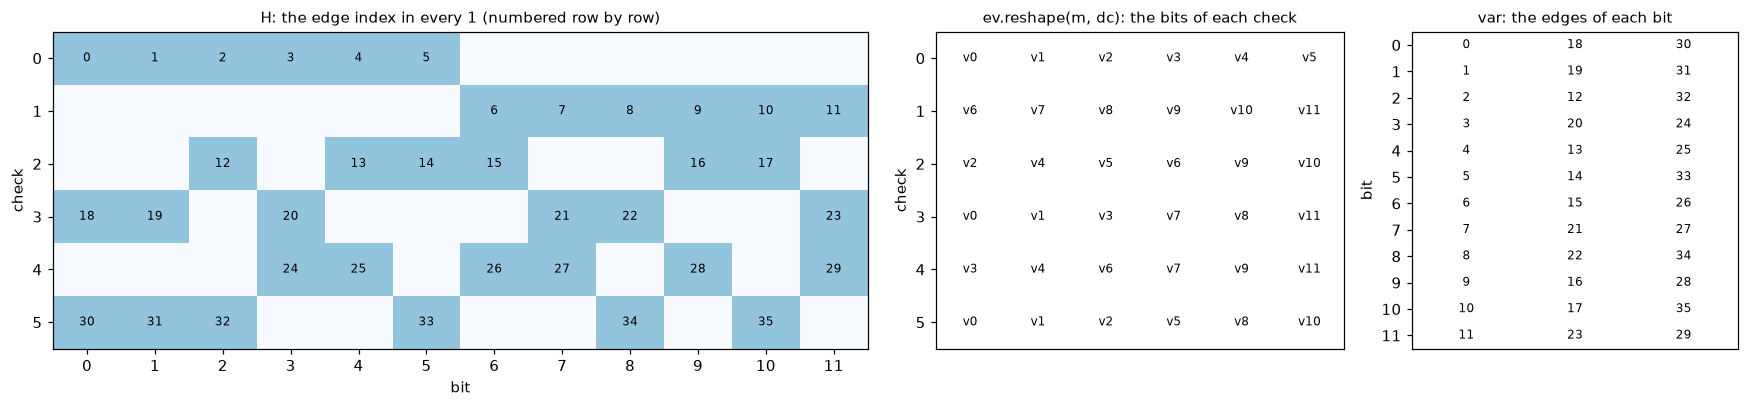

loo_prod matches the naive "product without oneself": True
check_update('spa') = ⊞ of the other inputs: True
min-sum example: inputs [ 2.47 -2.02 -3.86  3.23  1.08 -2.71] → outputs [-1.08  1.08  1.08 -1.08 -2.02  1.08]
layers of the working code: 3 of 168 checks each; every bit appears exactly once per layer: True


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2, 1, 0.8]})
Eidx = -np.ones(Ht.shape, int); Eidx[toy.ec, toy.ev] = np.arange(toy.E)
ax[0].imshow(Ht, cmap="Blues", vmin=0, vmax=2.5, aspect="auto"); ax[0].grid(False)
for (i, j), e in np.ndenumerate(Eidx):
    if e >= 0: ax[0].text(j, i, e, ha="center", va="center", fontsize=8)
ax[0].set_title("H: the edge index in every 1 (numbered row by row)", fontsize=10); ax[0].set_xlabel("bit"); ax[0].set_ylabel("check")
ax[0].set_xticks(range(toy.n)); ax[0].set_yticks(range(toy.m))
EV = toy.ev.reshape(toy.m, toy.dc)
ax[1].imshow(np.zeros_like(EV), cmap="Greys", vmin=0, vmax=1, aspect="auto"); ax[1].grid(False)
for (i, j), b in np.ndenumerate(EV): ax[1].text(j, i, f"v{b}", ha="center", va="center", fontsize=8)
ax[1].set_title("ev.reshape(m, dc): the bits of each check", fontsize=10); ax[1].set_ylabel("check"); ax[1].set_xticks([])
ax[2].imshow(np.zeros_like(toy.var), cmap="Greys", vmin=0, vmax=1, aspect="auto"); ax[2].grid(False)
for (j, k), e in np.ndenumerate(toy.var): ax[2].text(k, j, e, ha="center", va="center", fontsize=8)
ax[2].set_title("var: the edges of each bit", fontsize=10); ax[2].set_ylabel("bit"); ax[2].set_xticks([]); ax[2].set_yticks(range(toy.n))
plt.tight_layout(); plt.show()

t = np.tanh(rng.normal(0, 2, (4, DC)) / 2)
naive = np.array([[np.prod(np.delete(row, i)) for i in range(DC)] for row in t])
print("loo_prod matches the naive \"product without oneself\":", np.allclose(loo_prod(t), naive))
Lt = rng.normal(0, 3, (3, DC))
naive_bp = np.array([[boxplus(*np.delete(row, i)) for i in range(DC)] for row in Lt])
print("check_update('spa') = ⊞ of the other inputs:", np.allclose(check_update(Lt, "spa"), naive_bp))
print("min-sum example: inputs", np.round(Lt[0], 2), "→ outputs", np.round(check_update(Lt[:1], "ms", 1.0)[0], 2))
print(f"layers of the working code: {len(code.layers)} of {len(code.layers[0]) // code.dc} checks each; "
      f"every bit appears exactly once per layer: {all(np.bincount(code.ev[e], minlength=code.n).max() == 1 for e in code.layers)}")

# Part II. A length-1008 code at work

## 10. Iterations from the inside
100 frames at `EBN0_DB`. Left: how many bits in each frame are wrong after each iteration. Errors vanish **like an avalanche**. While there are few reliable bits, the checks give almost nothing. Once there are enough, they pull their neighbours through the checks, and those pull theirs. Some frames never converge; that is the FER at this code length.

Middle: what the **decoder itself** sees, the number of unsatisfied checks. It doesn't know the errors, but it does know the syndrome, and that is what it stops on.

Right: the distribution of the a-posteriori $x\cdot L$ over iterations. The mass moves right, and confidence grows by orders of magnitude.

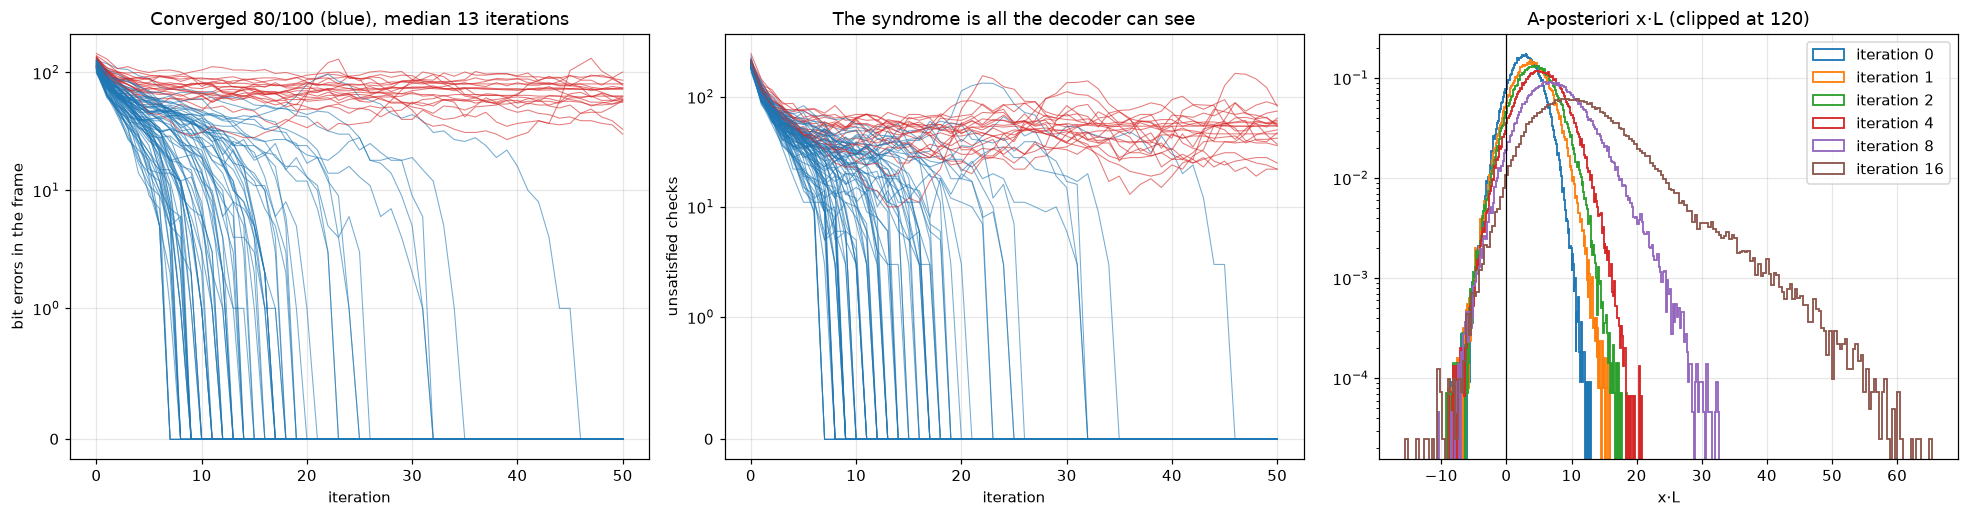

Channel errors (before decoding): 117 bits per frame out of 1008 (11.6%)
After decoding: BER = 1.24e-02, FER = 0.20


In [14]:
F = 100
U = rng.integers(0, 2, (F, code.k))
C = code.encode(U); X = 1 - 2.0 * C; Xe = X[:, code.ev]
_, L, _ = channel(C, EBN0_DB, code.R, rng)
hist = []
def rec(it, Lv, Lcv):
    hist.append(dict(xL=(Lv * X).astype(np.float32), err=(Lv * X < 0).sum(1),
                     Icv=mi(Lcv, Xe), Ivc=mi(Lv[:, code.ev] - Lcv, Xe),
                     unsat=((Lv < 0).astype(np.float32) @ code.Hf.T % 2).sum(1),
                     msg=((Lv[:, code.ev] - Lcv) * Xe, Lcv * Xe) if it in (1, 3, 6) else None))
Ch, nit = code.decode(L, MAX_ITER, "spa", cb=rec)
conv = code.syndrome_ok(Ch)
E = np.array([h["err"] for h in hist])

US = np.array([h["unsat"] for h in hist])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for f in range(F):
    ax[0].plot(E[:, f], color="C0" if conv[f] else "C3", lw=0.7, alpha=0.6)
    ax[1].plot(US[:, f], color="C0" if conv[f] else "C3", lw=0.7, alpha=0.6)
ax[1].set_yscale("symlog", linthresh=1); ax[1].set_xlabel("iteration"); ax[1].set_ylabel("unsatisfied checks")
ax[1].set_title("The syndrome is all the decoder can see")
ax[0].set_yscale("symlog", linthresh=1); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("bit errors in the frame")
ax[0].set_title(f"Converged {conv.sum()}/{F} (blue), median {np.median(nit[conv]):.0f} iterations")
for it in [0, 1, 2, 4, 8, 16]:
    if it < len(hist):
        ax[2].hist(np.clip(hist[it]["xL"].ravel(), -20, 120), 200, density=True, histtype="step", lw=1.2, label=f"iteration {it}")
ax[2].set_yscale("log"); ax[2].axvline(0, color="k", lw=0.8); ax[2].legend()
ax[2].set_title("A-posteriori x·L (clipped at 120)"); ax[2].set_xlabel("x·L")
plt.tight_layout(); plt.show()

print(f"Channel errors (before decoding): {E[0].mean():.0f} bits per frame out of {code.n} ({E[0].mean()/code.n:.1%})")
print(f"After decoding: BER = {np.mean(Ch[:, code.info] != U):.2e}, FER = {1 - conv.mean():.2f}")

## 11. The Gaussian approximation and the J-function
To predict the decoder without simulating it, we describe the message distribution with **a single number**. If an LLR $\sim\mathcal N(\sigma^2/2,\;\sigma^2)$ (the symmetry condition from section 5), all the information about the bit that it carries is
$$J(\sigma)=1-\mathbb E\big[\log_2(1+e^{-L})\big],\qquad L\sim\mathcal N(\sigma^2/2,\sigma^2),$$
a monotone function from 0 (σ=0, we know nothing) to 1 (σ→∞). In the primitives, $J$ is tabulated with Gauss–Hermite quadrature and $J^{-1}$ by inverse interpolation.

**Why σ is convenient.** A bit node adds independent LLRs → means and variances add, i.e. $\sigma^2$ adds. So $I_\text{out}=J\big(\sqrt{\textstyle\sum\sigma_i^2}\big)=J\big(\sqrt{\sum J^{-1}(I_i)^2}\big)$, which is exact for Gaussian inputs.

Left: $J(\sigma)$ and a Monte Carlo check. Right: actual messages from section 10 at iteration 3. Bit→check messages (a sum of several LLRs) are **close** to the Gaussian $\mathcal N(\mu,2\mu)$; check→bit messages are not (a sharp peak at zero and heavy tails, the result of ⊞). That is why the check-node formula in EXIT is only an approximation, and the Gaussian threshold differs from the exact one by a few hundredths of a dB (section 13).

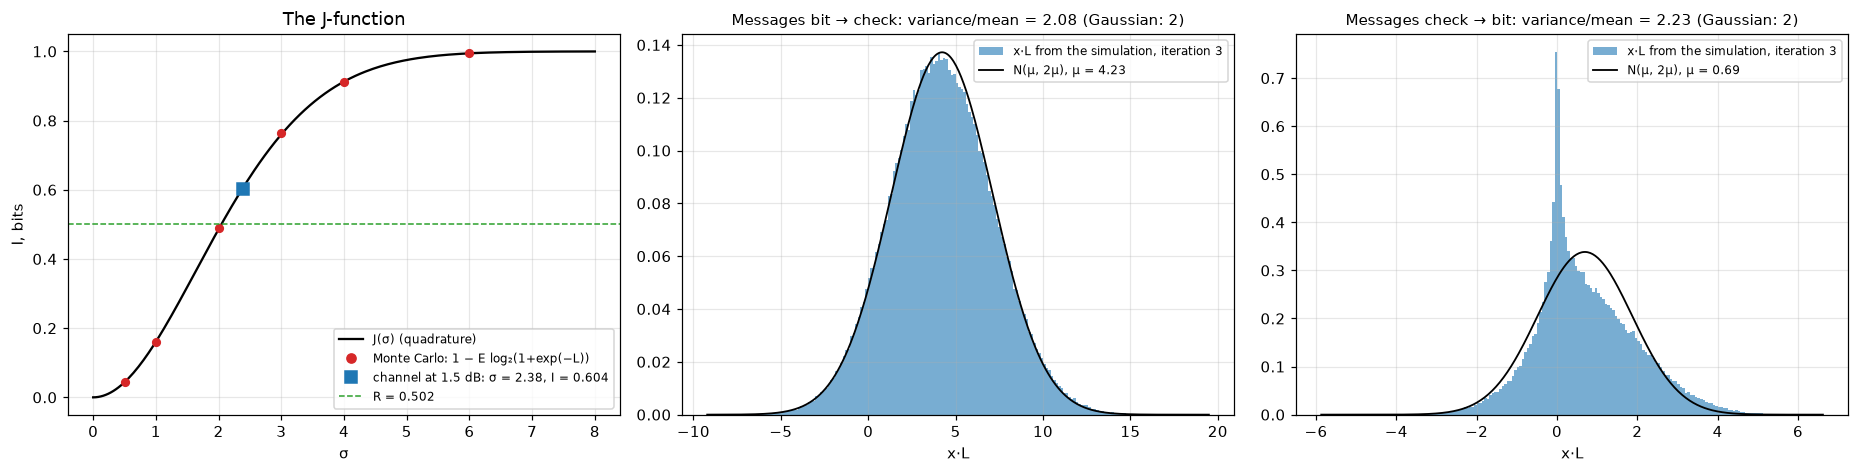

In [15]:
sg = np.linspace(0, 8, 200)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].plot(sg, J(sg), "k", label="J(σ) (quadrature)")
for s_ in [0.5, 1, 2, 3, 4, 6]:
    Ls = rng.normal(s_ ** 2 / 2, s_, 200000)
    ax[0].plot(s_, mi(Ls, 1), "C3o", ms=5)
ax[0].plot([], [], "C3o", label="Monte Carlo: 1 − E log₂(1+exp(−L))")
s_ch = sch(EBN0_DB, code.R)
ax[0].plot(s_ch, J(s_ch), "C0s", ms=8, label=f"channel at {EBN0_DB} dB: σ = {s_ch:.2f}, I = {J(s_ch):.3f}")
ax[0].axhline(code.R, color="C2", ls="--", lw=1, label=f"R = {code.R:.3f}")
ax[0].set_xlabel("σ"); ax[0].set_ylabel("I, bits"); ax[0].legend(fontsize=8); ax[0].set_title("The J-function")
for a, k, name in [(ax[1], 0, "bit → check"), (ax[2], 1, "check → bit")]:
    d = hist[3]["msg"][k].ravel()
    d = d[np.abs(d) < 40]
    m_ = d.mean()
    a.hist(d, 200, density=True, alpha=0.6, label="x·L from the simulation, iteration 3")
    lz = np.linspace(d.min(), d.max(), 400)
    a.plot(lz, np.exp(-(lz - m_) ** 2 / (4 * m_)) / np.sqrt(4 * np.pi * m_), "k", lw=1.2, label=f"N(μ, 2μ), μ = {m_:.2f}")
    a.set_title(f"Messages {name}: variance/mean = {d.var() / m_:.2f} (Gaussian: 2)", fontsize=10); a.legend(fontsize=8); a.set_xlabel("x·L")
plt.tight_layout(); plt.show()

## 12. The threshold: EXIT chart
If the edge messages are Gaussian LLRs, each one is described by a single number: its mutual information $I$ with the bit. The bit node and the check node then become two transfer functions $I_\text{out}=f(I_\text{in})$, and the decoder walks between them like a staircase.

- **Bit node**: LLRs add, and so do their variances: $I_{E,V}=J\big(\sqrt{(d_v-1)\,J^{-1}(I_A)^2+\sigma_\text{ch}^2}\big)$. **Only this curve** depends on the channel.
- **Check node**: $I_{E,C}\approx1-J\big(\sqrt{d_c-1}\,J^{-1}(1-I_A)\big)$.

As long as there is a **tunnel** between the curves, the staircase reaches $I=1$ (error-free as $n\to\infty$). The threshold is the $E_b/N_0$ at which the tunnel closes. Left: below the threshold. Right: the operating point, with dots measured in the section 10 simulation. The simulation follows the theory for the first steps and then falls behind: on a finite graph, a bit's neighbourhood closes into cycles after 3–4 iterations (girth 6–8, section 3), messages stop being independent, and frames that didn't converge drag the average down.

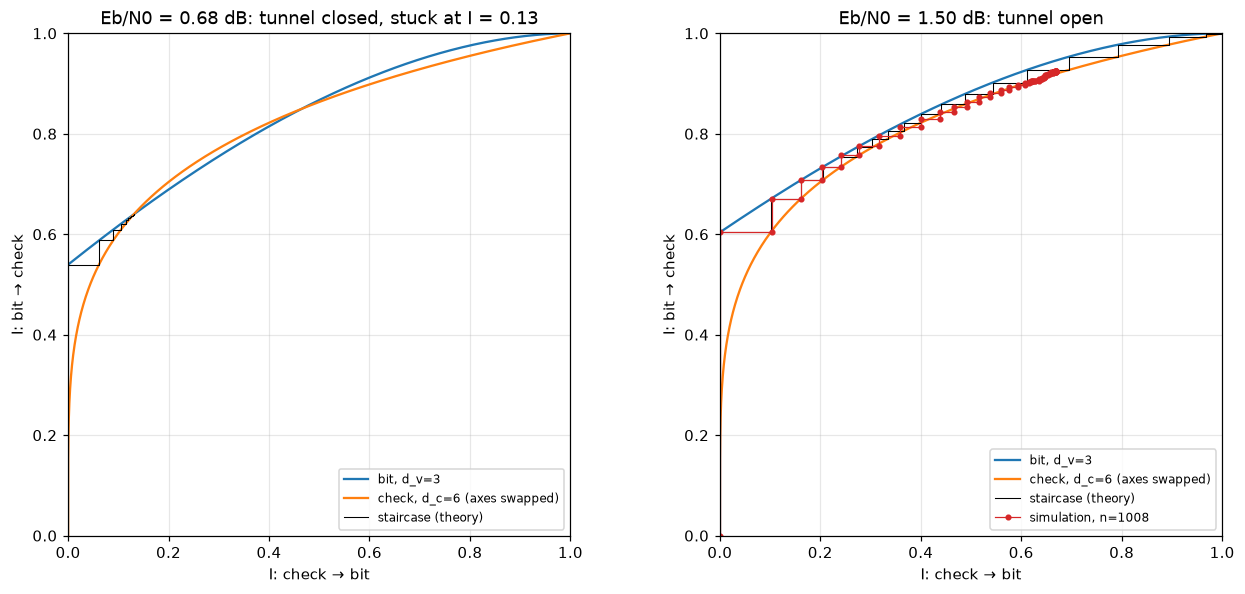

EXIT threshold: 1.08 dB (exact density evolution for (3,6): 1.11 dB), Shannon: 0.20 dB — the regular code loses 0.9 dB; irregular degree distributions fit the two curves to each other.


In [16]:
def stairs(Ic, Iv):
    xs, ys = [Ic[0]], [0.0]
    for l in range(len(Iv)):
        xs += [Ic[l], Ic[l + 1]]; ys += [Iv[l], Iv[l]]
    return xs, ys

Ia = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, e in zip(ax, [TH - 0.4, EBN0_DB]):
    a.plot(Ia, exit_v(Ia, e, code.R), "C0", lw=1.5, label=f"bit, d_v={DV}")
    a.plot(exit_c(Ia), Ia, "C1", lw=1.5, label=f"check, d_c={DC} (axes swapped)")
    Ic, Iv = de_traj(e, code.R, 300)
    a.plot(*stairs(Ic, Iv), "k", lw=0.7, label="staircase (theory)")
    st = "open" if Ic[-1] > 0.9999 else f"closed, stuck at I = {Ic[-1]:.2f}"
    a.set_title(f"Eb/N0 = {e:.2f} dB: tunnel {st}")
    a.set_xlabel("I: check → bit"); a.set_ylabel("I: bit → check"); a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect("equal")
Icv, Ivc = np.array([h["Icv"] for h in hist]), np.array([h["Ivc"] for h in hist])
ax[1].plot(*stairs(Icv, Ivc[:-1]), "C3o-", ms=3, lw=0.8, label="simulation, n=%d" % code.n)
for a in ax: a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"EXIT threshold: {TH:.2f} dB (exact density evolution for (3,6): 1.11 dB), Shannon: {SH:.2f} dB — "
      f"the regular code loses {TH - SH:.1f} dB; irregular degree distributions fit the two curves to each other.")

## 13. Monte Carlo density evolution
EXIT assumes that all messages are Gaussian. A more accurate approach tracks **the distribution itself** (density evolution, Richardson–Urbanke). As $n\to\infty$ the graph is locally a tree, and all messages of one iteration are identically distributed and independent. We represent the distribution by a **population** of $N$ samples and apply the node rules to it, drawing the inputs at random from the population:

1. start: $L_\text{ch}\sim\mathcal N(\mu,2\mu)$ (the all-zero word was sent, section 4), $L_{c\to v}=0$;
2. bit node: $L_{v\to c}=L_\text{ch}+\sum_{d_v-1}L_{c\to v}$ (random samples);
3. check node: $L_{c\to v}=\boxplus_{d_c-1}L_{v\to c}$;
4. bit error probability $P_e=P\big(L_\text{ch}+\sum_{d_v}L_{c\to v}<0\big)$.

Above the threshold $P_e\to0$; below it, $P_e$ gets stuck at a **nonzero fixed point**. The closer to the threshold, the longer the "plateau" (the bottleneck between the EXIT curves). We find the threshold by bisection.

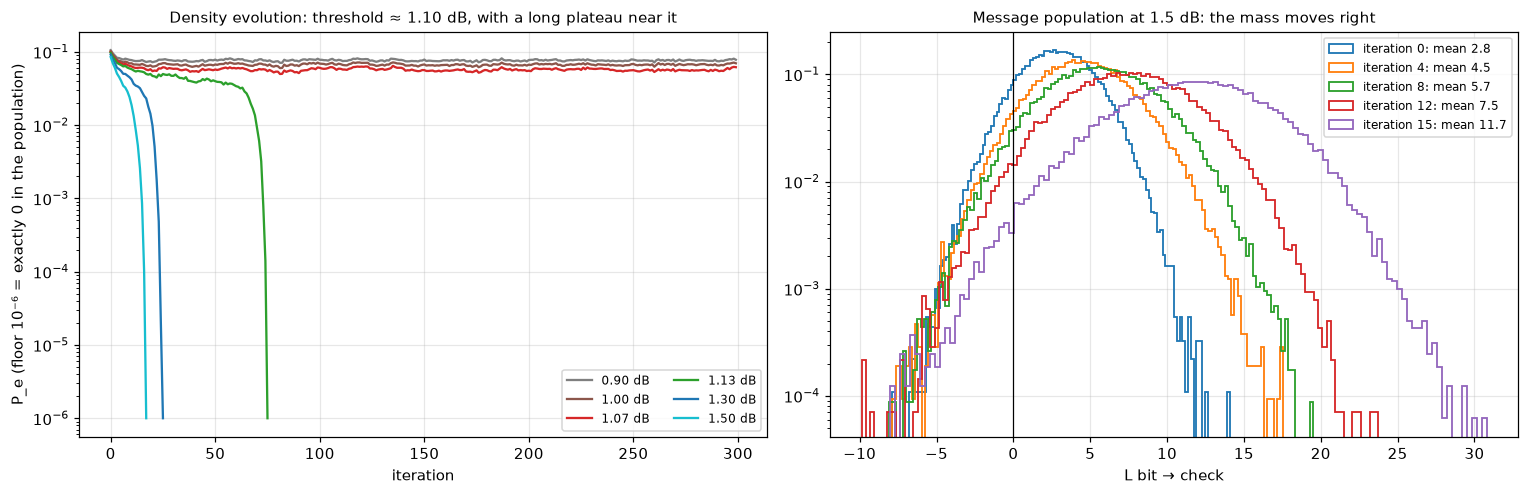

(3,6) threshold: density evolution 1.10 dB (literature 1.11), Gaussian EXIT 1.08 dB, Shannon 0.20 dB


In [17]:
def de_mc(e, iters=300, N=50000, seed=0, keep=()):
    r_ = np.random.default_rng(seed)
    mu_ = 4 * code.R * 10 ** (e / 10)              # μ = 2/σ² = 4R·Eb/N0
    Lc = r_.normal(mu_, np.sqrt(2 * mu_), N)
    Lcv, pe, snap = np.zeros(N), [], {}
    for it in range(iters):
        Lvc = Lc + Lcv[r_.integers(0, N, (DV - 1, N))].sum(0)
        if it in keep: snap[it] = Lvc.copy()
        Lcv = boxplus(*Lvc[r_.integers(0, N, (DC - 1, N))])
        Lp = Lc + Lcv[r_.integers(0, N, (DV, N))].sum(0)
        pe.append(np.mean(Lp < 0))
        if pe[-1] == 0: break
    return np.array(pe), snap

lo, hi = 0.8, 1.4
for _ in range(6):
    mid = (lo + hi) / 2
    lo, hi = (lo, mid) if de_mc(mid)[0][-1] < 1e-4 else (mid, hi)
TH_DE = hi

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for e, col in zip([0.9, 1.0, TH_DE - 0.03, TH_DE + 0.03, 1.3, EBN0_DB], ["C7", "C5", "C3", "C2", "C0", "C9"]):
    pe, _ = de_mc(e)
    ax[0].semilogy(np.maximum(pe, 1e-6), col, label=f"{e:.2f} dB")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("P_e (floor 10⁻⁶ = exactly 0 in the population)"); ax[0].legend(fontsize=8, ncol=2)
ax[0].set_title(f"Density evolution: threshold ≈ {TH_DE:.2f} dB, with a long plateau near it", fontsize=10)
_, snap = de_mc(EBN0_DB, keep=(0, 4, 8, 12, 15))
for it, d in snap.items():
    d = d[np.abs(d) < 80]
    ax[1].hist(d, 120, density=True, histtype="step", lw=1.2, label=f"iteration {it}: mean {d.mean():.1f}")
ax[1].set_yscale("log"); ax[1].axvline(0, color="k", lw=0.8); ax[1].legend(fontsize=8); ax[1].set_xlabel("L bit → check")
ax[1].set_title(f"Message population at {EBN0_DB} dB: the mass moves right", fontsize=10)
plt.tight_layout(); plt.show()
print(f"(3,6) threshold: density evolution {TH_DE:.2f} dB (literature 1.11), Gaussian EXIT {TH:.2f} dB, Shannon {SH:.2f} dB")

## 14. Decoder schedule: flooding vs. layered
In section 10 the decoder uses a **flooding** schedule: all checks are updated at once from the previous iteration's messages. **Layered**: the checks are split into layers that share no bits. After a layer is processed, the a-posteriori LLRs of its bits are updated right away, and the next layer already sees the fresh information:
$$L_{v\to c}=L_v-L_{c\to v}^\text{old},\qquad L_{c\to v}^\text{new}=\boxplus(\dots),\qquad L_v\leftarrow L_{v\to c}+L_{c\to v}^\text{new}.$$
It is the same as Gauss–Seidel vs. Jacobi in iterative solvers: information spreads faster, and roughly half as many iterations are needed. It also saves memory, since only $L_v$ and $L_{c\to v}$ are stored. In 5G NR and Wi-Fi hardware a layer is one block row of the quasi-cyclic matrix.

flood   : FER = 0.233, BER = 1.4e-02, iterations of converged frames: mean 15.0, median 13


layered : FER = 0.185, BER = 1.2e-02, iterations of converged frames: mean 9.1, median 7


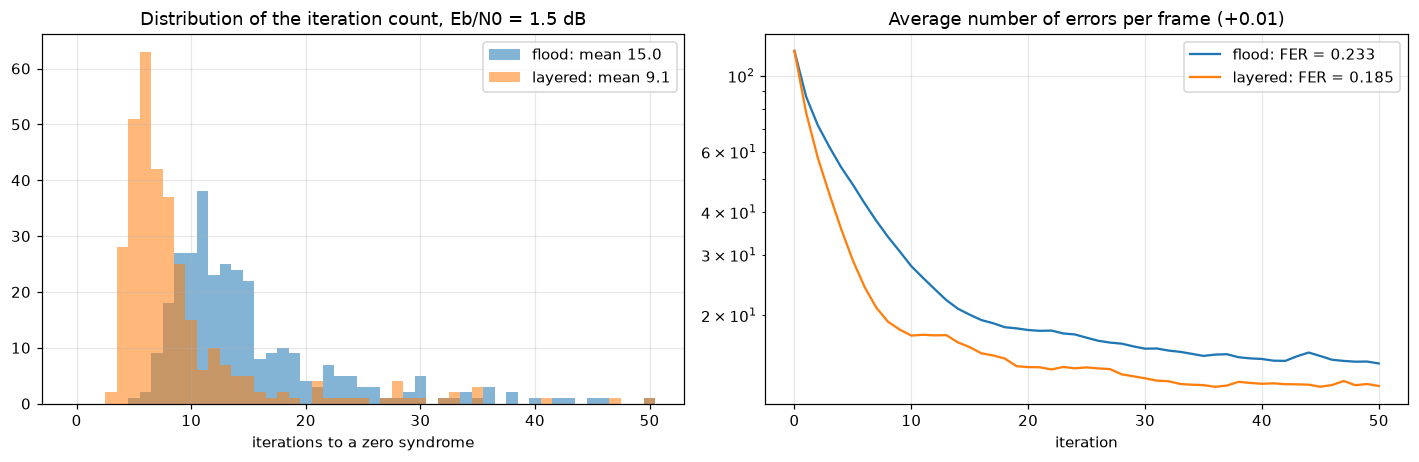

In [18]:
F14 = 400
U = rng.integers(0, 2, (F14, code.k)); C = code.encode(U); X = 1 - 2.0 * C
_, L14, _ = channel(C, EBN0_DB, code.R, rng)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for sch_, col in [("flood", "C0"), ("layered", "C1")]:
    tr = []
    Ch, nit = code.decode(L14, MAX_ITER, "spa", schedule=sch_, cb=lambda it, Lv, Lcv: tr.append((Lv * X < 0).sum(1).mean()))
    ok = code.syndrome_ok(Ch)
    ax[0].hist(nit[ok], np.arange(0, MAX_ITER + 2) - 0.5, alpha=0.55, color=col, label=f"{sch_}: mean {nit[ok].mean():.1f}")
    ax[1].semilogy(np.array(tr) + 0.01, col, label=f"{sch_}: FER = {1 - ok.mean():.3f}")
    print(f"{sch_:8s}: FER = {1 - ok.mean():.3f}, BER = {np.mean(Ch[:, code.info] != U):.1e}, iterations of converged frames: mean {nit[ok].mean():.1f}, median {np.median(nit[ok]):.0f}")
ax[0].set_xlabel("iterations to a zero syndrome"); ax[0].set_title(f"Distribution of the iteration count, Eb/N0 = {EBN0_DB} dB"); ax[0].legend()
ax[1].set_xlabel("iteration"); ax[1].set_title("Average number of errors per frame (+0.01)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 15. The waterfall: BER/FER vs. Eb/N0
Sum-product (exact BP), normalized min-sum (what goes into hardware: only comparisons and additions) and Gallager's **hard-decision bit-flipping**: the decoder sees only the signs of $y$ and in each iteration flips the bits with the most unsatisfied checks. The gap between it and BP is the price of throwing away the "soft" information ($|L|$). The dashed lines are the Shannon limit and the EXIT threshold. The threshold is the $n\to\infty$ asymptote; at finite length the waterfall shifts right. Right: average decoding time. At higher SNR the decoder converges in a few iterations.

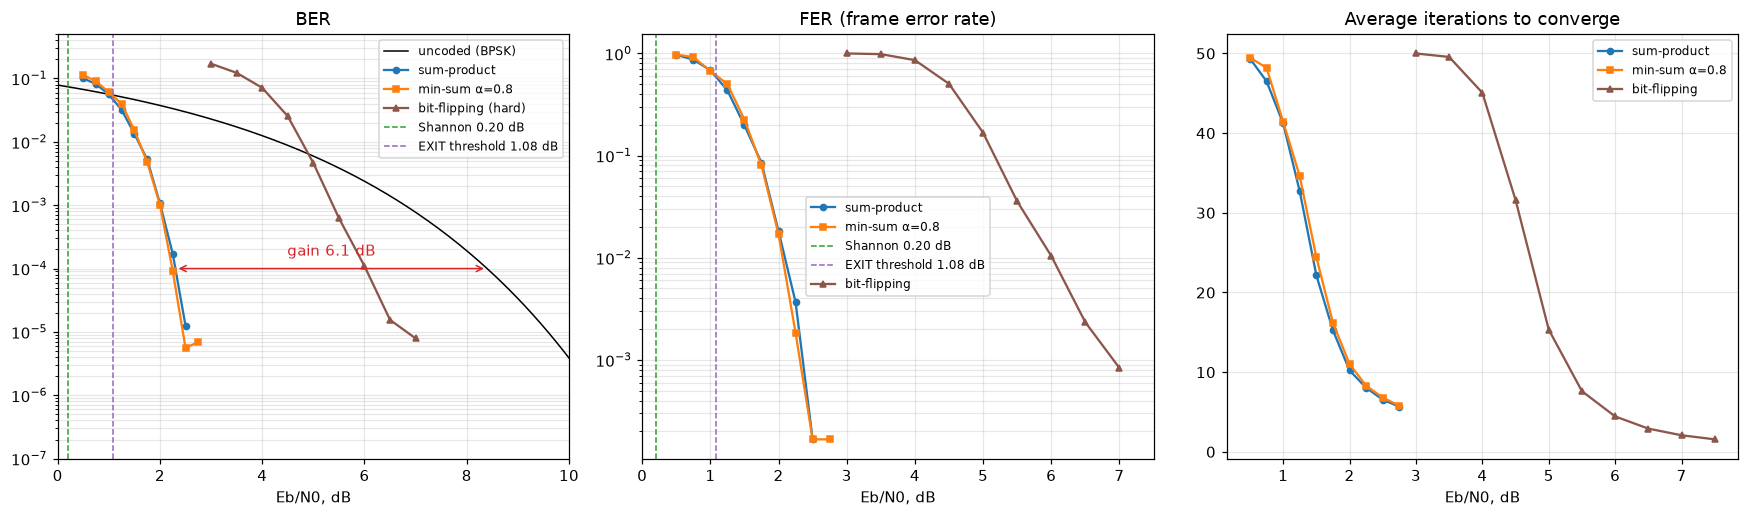

 Eb/N0 |  BER SPA   FER SPA  iter |  BER MS    FER MS   iter | frames SPA
  0.50 |  1.0e-01  9.7e-01  49.4 |  1.1e-01  9.7e-01  49.5 | 200
  0.75 |  8.1e-02  8.7e-01  46.5 |  9.0e-02  9.2e-01  48.2 | 200
  1.00 |  5.6e-02  6.9e-01  41.2 |  6.0e-02  6.8e-01  41.4 | 200
  1.25 |  3.2e-02  4.3e-01  32.7 |  4.0e-02  5.0e-01  34.6 | 200
  1.50 |  1.3e-02  2.0e-01  22.2 |  1.5e-02  2.3e-01  24.4 | 400
  1.75 |  5.3e-03  8.5e-02  15.3 |  4.8e-03  8.0e-02  16.2 | 800
  2.00 |  1.1e-03  1.8e-02  10.2 |  1.0e-03  1.7e-02  11.0 | 2800
  2.25 |  1.7e-04  3.7e-03   8.0 |  9.2e-05  1.8e-03   8.3 | 6000
  2.50 |  1.3e-05  1.7e-04   6.5 |  5.6e-06  1.7e-04   6.8 | 6000
  2.75 |  0.0e+00  0.0e+00   5.7 |  6.9e-06  1.7e-04   5.8 | 6000

BER = 1e-04: uncoded 8.4 dB, LDPC 2.3 dB → coding gain 6.1 dB at the cost of twice the bandwidth (R = 1/2)
bit-flipping: BER = 1e-04 at 6.0 dB → soft decisions (BP) beat hard ones by 3.7 dB on the same code


In [19]:
def simulate(ebn0_list, algo, min_fe=50, max_frames=6000, batch=200):
    res = []
    for e in ebn0_list:
        be = fe = nf = its = 0
        while fe < min_fe and nf < max_frames:
            U = rng.integers(0, 2, (batch, code.k))
            _, L, _ = channel(code.encode(U), e, code.R, rng)
            Ch, nit = code.bitflip(L, MAX_ITER) if algo == "bf" else code.decode(L, MAX_ITER, algo, ALPHA_MS)
            err = Ch[:, code.info] != U
            be += err.sum(); fe += err.any(1).sum(); nf += batch; its += nit.sum()
        res.append((be / (nf * code.k), fe / nf, its / nf, nf))
    return np.array(res)

ebn0 = np.arange(0.5, 2.76, 0.25)
res = {"sum-product": simulate(ebn0, "spa"), f"min-sum α={ALPHA_MS}": simulate(ebn0, "ms")}
ebn0_bf = np.arange(3.0, 7.6, 0.5)
res_bf = simulate(ebn0_bf, "bf")

r = res["sum-product"]
target = 1e-4                                      # below this the statistics are thin (0 errors in 6000 frames ≠ BER 0)
i = np.argmax((r[:, 0] < target) & (r[:, 0] > 0))  # first non-zero point below target, interpolate in log BER
e_code = np.interp(np.log10(target), np.log10(r[[i, i - 1], 0]), ebn0[[i, i - 1]])
e_unc = brentq(lambda e: 0.5 * erfc(np.sqrt(10 ** (e / 10))) - target, 0, 15)

eb = np.linspace(0, 10, 200)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].semilogy(eb, 0.5 * erfc(np.sqrt(10 ** (eb / 10))), "k-", lw=1, label="uncoded (BPSK)")
for (name, rr), mk in zip(res.items(), "os"):
    ok = rr[:, 0] > 0
    ax[0].semilogy(ebn0[ok], rr[ok, 0], mk + "-", ms=4, label=name)
    ax[1].semilogy(ebn0[rr[:, 1] > 0], rr[rr[:, 1] > 0, 1], mk + "-", ms=4, label=name)
    ax[2].plot(ebn0, rr[:, 2], mk + "-", ms=4, label=name)
okb = res_bf[:, 0] > 0
ax[0].semilogy(ebn0_bf[okb], res_bf[okb, 0], "^-", ms=4, color="C5", label="bit-flipping (hard)")
for a in ax[:2]:
    a.axvline(SH, color="C2", ls="--", lw=1, label=f"Shannon {SH:.2f} dB")
    a.axvline(TH, color="C4", ls="--", lw=1, label=f"EXIT threshold {TH:.2f} dB")
ax[0].annotate("", xy=(e_code, target), xytext=(e_unc, target), arrowprops=dict(arrowstyle="<->", color="C3"))
ax[0].text((e_code + e_unc) / 2, target * 1.6, f"gain {e_unc - e_code:.1f} dB", color="C3", ha="center")
ax[0].set_xlim(0, 10); ax[0].set_ylim(1e-7, 0.5)
ax[1].semilogy(ebn0_bf[res_bf[:, 1] > 0], res_bf[res_bf[:, 1] > 0, 1], "^-", ms=4, color="C5", label="bit-flipping")
ax[2].plot(ebn0_bf, res_bf[:, 2], "^-", ms=4, color="C5", label="bit-flipping")
ax[1].set_xlim(0, 7.5)
ax[0].set_title("BER"); ax[1].set_title("FER (frame error rate)"); ax[2].set_title("Average iterations to converge")
for a in ax: a.set_xlabel("Eb/N0, dB"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print(" Eb/N0 |  BER SPA   FER SPA  iter |  BER MS    FER MS   iter | frames SPA")
for i, e in enumerate(ebn0):
    s, q = list(res.values())[0][i], list(res.values())[1][i]
    print(f" {e:5.2f} | {s[0]:8.1e} {s[1]:8.1e} {s[2]:5.1f} | {q[0]:8.1e} {q[1]:8.1e} {q[2]:5.1f} | {int(s[3])}")

print(f"\nBER = {target:.0e}: uncoded {e_unc:.1f} dB, LDPC {e_code:.1f} dB → coding gain {e_unc - e_code:.1f} dB "
      f"at the cost of twice the bandwidth (R = 1/2)")

i = np.argmax((res_bf[:, 0] < target) & (res_bf[:, 0] > 0))
e_bf = np.interp(np.log10(target), np.log10(res_bf[[i, i - 1], 0]), ebn0_bf[[i, i - 1]]) if i > 0 else np.nan
print(f"bit-flipping: BER = {target:.0e} at {e_bf:.1f} dB → soft decisions (BP) beat hard ones by {e_bf - e_code:.1f} dB on the same code")

## 16. Code length and min-sum normalization
**Length.** The threshold (sections 12–13) is a property of the $(d_v,d_c)$ ensemble as $n\to\infty$. A finite code differs in two ways: (1) the noise realization over $n$ symbols fluctuates around its mean, and with short $n$ a "bad" frame comes up more often, so the waterfall is shallower; (2) the cycles are shorter, so the messages are correlated. As $n$ grows, the waterfall gets steeper and moves toward the threshold, but never crosses it. Each length gets its own code from the same construction; each point uses at most 2000 frames, so FER below ~$10^{-3}$ means single errors (and points with zero errors are not drawn).

**Normalization.** Min-sum FER as a function of $\alpha$ at two $E_b/N_0$ values; the horizontal lines are exact sum-product. With $\alpha=1$ the checks overestimate their confidence (section 6), and wrong messages are too "loud". With $\alpha$ too small it's the other way round: correct messages are underweighted and convergence is slow.

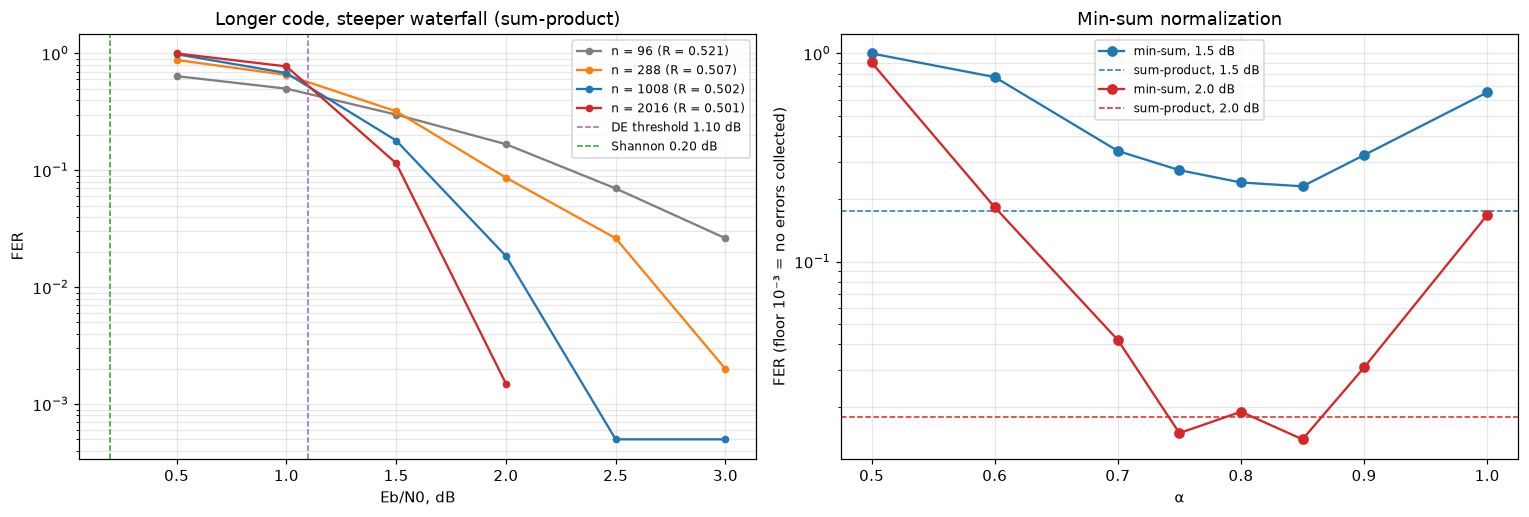

FER by length:
  Eb/N0       n=96     n=288    n=1008    n=2016
   0.50   6.40e-01  8.80e-01  9.85e-01  1.00e+00
   1.00   5.00e-01  6.55e-01  6.80e-01  7.75e-01
   1.50   3.00e-01  3.20e-01  1.80e-01  1.15e-01
   2.00   1.68e-01  8.67e-02  1.85e-02  1.50e-03
   2.50   7.00e-02  2.62e-02  5.00e-04  0.00e+00
   3.00   2.62e-02  2.00e-03  5.00e-04  0.00e+00
1.5 dB: best α = 0.85, min-sum FER 0.230 vs. sum-product 0.175, α=1: 0.650
2.0 dB: best α = 0.85, min-sum FER 0.014 vs. sum-product 0.018, α=1: 0.168


In [20]:
def sim_fer(cd, e, algo="spa", alpha=ALPHA_MS, min_fe=40, max_frames=2000, batch=200):
    fe = nf = 0
    while fe < min_fe and nf < max_frames:
        U = rng.integers(0, 2, (batch, cd.k))
        _, L, _ = channel(cd.encode(U), e, cd.R, rng)
        Ch, _ = cd.decode(L, MAX_ITER, algo, alpha)
        fe += (Ch[:, cd.info] != U).any(1).sum(); nf += batch
    return fe / nf

lens = [96, 288, N_CODE, 2016]
codes = {n_: (code if n_ == N_CODE else LDPC(gallager_H(n_, DV, DC, np.random.default_rng(SEED)))) for n_ in lens}
eb16 = np.arange(0.5, 3.01, 0.5)
fer_n = {n_: np.array([sim_fer(cd, e) for e in eb16]) for n_, cd in codes.items()}

alphas = np.array([0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 1.0])
eb_a = [1.5, 2.0]
fer_a = {e: np.array([sim_fer(code, e, "ms", a_, max_frames=1000) for a_ in alphas]) for e in eb_a}
fer_spa = {e: sim_fer(code, e, "spa", max_frames=1000) for e in eb_a}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for n_, col in zip(lens, ["C7", "C1", "C0", "C3"]):
    f_ = fer_n[n_]; ok = f_ > 0
    ax[0].semilogy(eb16[ok], f_[ok], "o-", ms=4, color=col, label=f"n = {n_} (R = {codes[n_].R:.3f})")
ax[0].axvline(TH_DE, color="C4", ls="--", lw=1, label=f"DE threshold {TH_DE:.2f} dB"); ax[0].axvline(SH, color="C2", ls="--", lw=1, label=f"Shannon {SH:.2f} dB")
ax[0].set_xlabel("Eb/N0, dB"); ax[0].set_ylabel("FER"); ax[0].legend(fontsize=8); ax[0].set_title("Longer code, steeper waterfall (sum-product)")
ax[0].grid(which="both", alpha=0.3)
for e, col in zip(eb_a, ["C0", "C3"]):
    ax[1].semilogy(alphas, np.maximum(fer_a[e], 1e-3), "o-", color=col, label=f"min-sum, {e} dB")
    ax[1].axhline(max(fer_spa[e], 1e-3), color=col, ls="--", lw=1, label=f"sum-product, {e} dB")
ax[1].set_xlabel("α"); ax[1].set_ylabel("FER (floor 10⁻³ = no errors collected)"); ax[1].legend(fontsize=8)
ax[1].set_title("Min-sum normalization"); ax[1].grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print("FER by length:"); print("  Eb/N0 " + "".join(f"{f'n={n_}':>10s}" for n_ in lens))
for j, e in enumerate(eb16): print(f"  {e:5.2f} " + "".join(f"{fer_n[n_][j]:10.2e}" for n_ in lens))
for e in eb_a:
    print(f"{e} dB: best α = {alphas[np.argmin(fer_a[e])]}, min-sum FER {fer_a[e].min():.3f} vs. sum-product {fer_spa[e]:.3f}, α=1: {fer_a[e][-1]:.3f}")

## Comparison with CDMA
DSSS from the CDMA notebook is also a code: a **repetition code** with rate $R=1/N$, where each bit is simply repeated $N$ times. Against white noise it gives nothing (the curve is BPSK): the bit energy is the same, just smeared over $N$ chips. LDPC at $R=1/2$ gives 6–7 dB. Its parity bits don't copy the data, they **tie it together**, so every error has to "break through" several independent constraints.

| | DSSS (repetition) | LDPC (3,6) |
|---|---|---|
| Redundancy | $N=1023$ | 2 |
| Gain against AWGN (BER $10^{-4}$…$10^{-5}$) | 0 dB | 6–7 dB |
| Against narrowband interference | $10\log_{10}N$ = 30 dB | ~0 (needs an interleaver) |
| Decoder | a single correlator | iterative LLR exchange |

Real systems use both: spreading/OFDM deals with the channel, the code with the residual noise. LTE encodes data with a turbo code (the same iterative LLR exchange, but two convolutional codes instead of a graph). LDPC arrived in 5G NR and Wi-Fi as quasi-cyclic matrices, built from cyclic shifts of $Z\times Z$ identity blocks so that the decoder can run in parallel.

## Things to try
- `EBN0_DB = 1.0`: below the threshold. In section 12 the tunnel is closed, in section 10 almost every frame gets stuck with about a hundred errors, and in section 13 the population stalls on a plateau
- `N_CODE = 96` / `4032`: the waterfall gets steeper with length and moves toward the threshold; the threshold itself doesn't change (section 16 shows several lengths at once). With small $n$ the girth in section 3 drops to 4–6
- `DV, DC = 4, 8` (same $R=1/2$): a worse threshold (~1.5 dB). More edges mean more constraints, but each is weaker
- `ALPHA_MS = 1.0`: plain min-sum overestimates check confidence ($\min|L|$ is larger than the exact value) and loses noticeably; the normalization compensates. At high SNR normalized min-sum can even beat exact BP: on a graph with cycles, BP itself is overconfident
- `gallager_H(..., fix_4cycles=False)`: keep the 4-cycles and watch the erroneous "echo" in BP
- in section 8, `channel(c8, 2.0, ...)`: more channel errors, and on the 12-bit code with 4-cycles BP starts to "loop": the LLRs oscillate instead of growing
- in section 14, `"ms"` instead of `"spa"`: layered speeds up min-sum too, by about the same number of iterations
- in section 13, `N=5000`: the population is small and the threshold "drifts". It is the same finite-length problem a real code has